# What should a Hong Kong host charge? A data-driven pricing benchmark for short- and mid-term rentals
**IS3240 Advanced Business Programming in Python – Group Project (code notebook)**

## 1. The business problem

Hong Kong has one of the most expensive and most regulated accommodation markets in the world. Operators of Airbnb-type
listings – from individual hosts renting a spare room to professional property managers running dozens of flats – face
the same recurring decision: **"what nightly price should I put on this listing?"**

* **Too high** and the listing sits empty; **too low** and the operator gives revenue away on every night booked.
* The market is *two markets in one*: Hong Kong law restricts renting out residential premises for fewer than 28 consecutive days
  without a licence, so a large share of listings are in practice **monthly rentals** whose nightly price is a fraction of a tourist stay.
* Price depends on many things at once (location, transit, size, amenities, who the host is) and hosts usually fall back on
  looking at a few "comparable" listings.

**Our objective:** use machine learning in Python to build a *pricing benchmark* that (i) predicts a fair asking price and a plausible
price band from information available **before the first guest arrives**, (ii) explains what drives price and by how much, (iii) flags
listings priced far from the benchmark and tests whether this is associated with weaker demand, and (iv) explains each price in plain language.
The users are *hosts and property managers*, *investors* (which segments and districts to choose) and, indirectly, *platforms and policy makers*.

## Roadmap
| Step | Question | Section |
|---|---|---|
| Problem and data | Why does it matter, what data do we have, what did we remove and why? | 1 – 3 |
| Market understanding | What does the market look like (stay types, geography, price map)? | 4 – 5 |
| Useful factors | Which factors might explain the price, why, and how are they computed? | 6 |
| Market segments | Which natural segments exist? (unsupervised learning) | 7 |
| Suitable models and performance | Which models, evaluated how, and how good is the benchmark? | 8 |
| Insight | Which factors matter? Who is over- or under-priced? | 9 – 11 |
| Action | How would a host use it, and why is the price what it is? | 12 – 13 |

**Data:** Inside Airbnb – Hong Kong (detailed listings and reviews, scraped 25 Sep 2026) plus the **MTR station locations from
OpenStreetMap** (Overpass API).

**How to run:** place the data files in `data/` and run all cells (*Restart & Run All*). The MTR stations are saved in
`data/mtr_stations.csv`, so the notebook also runs offline. Every figure and number quoted in the report is produced here and saved in `outputs/`.

## 2. Setup and data loading
We load the libraries, fix a random seed and the project folders, and read the three Inside Airbnb files (detailed listings, summary
listings and reviews). Then we audit the data: size, empty columns and how the price is stored.

In [1]:
# Libraries: pandas (tables), NumPy (arrays), matplotlib (charts), requests (web APIs), scikit-learn (machine learning), statsmodels (regression)
import os, re, json, glob, time, textwrap, warnings, contextlib, io
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count() or 1))
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import requests
try:   # optional: use the operating-system certificates for HTTPS (needed behind some antivirus programs)
    import truststore; truststore.inject_into_ssl()
except ImportError:
    pass
from sklearn.model_selection import GroupShuffleSplit, GroupKFold, GridSearchCV, cross_val_score, cross_val_predict
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, mean_absolute_error, r2_score
from sklearn.base import clone
import statsmodels.api as sm
import statsmodels.formula.api as smf

warnings.filterwarnings("ignore")
with contextlib.redirect_stderr(io.StringIO()):     # hides a harmless joblib message on Windows computers without the "wmic" tool
    from joblib.externals.loky import cpu_count
    cpu_count(only_physical_cores=True)
SEED = 42                                           # fixed random seed, so that the results are reproducible
np.random.seed(SEED)

In [2]:
# Project folders (the `if` makes the notebook work also when it is opened from a sub-folder)
ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent
DATA, OUT = ROOT / "data", ROOT / "outputs"
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

RESULTS = {}                                        # every number quoted in the report is collected here and saved in outputs/results.json
def save_results():
    with open(OUT / "results.json", "w", encoding="utf8") as f:
        json.dump(RESULTS, f, indent=2, default=lambda o: o.tolist() if hasattr(o, "tolist") else str(o))

# Common chart style: one colour-blind-safe palette
PAL = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100", magenta="#e87ba4", green="#008300", violet="#6250d6", red="#e34948",
           ink="#0b0b0b", ink2="#52514e", muted="#898781", surface="#fcfcfb")
CAT = [PAL[c] for c in ["blue", "orange", "aqua", "yellow", "magenta", "green", "violet", "red"]]
mpl.rcParams.update({"axes.facecolor": PAL["surface"], "font.size": 8, "axes.titlesize": 8.8, "axes.titleweight": "bold", "axes.titlelocation": "left",
                     "axes.spines.top": False, "axes.spines.right": False, "grid.color": "#e1e0d9", "axes.axisbelow": True, "legend.frameon": False})

def savefig(name, fig):
    """Save the figure in outputs/figures (the report uses these files) and show it."""
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight", dpi=220, facecolor="white")
    plt.show()

def pct(x, d=0):
    """pct(0.256) gives '26%'."""
    return f"{100*x:.{d}f}%"

In [3]:
# Load the files. L = listings (one row per listing), S = summary file (only used for a check), R = reviews (one row per review)
L = pd.read_csv(sorted(glob.glob(str(DATA / "listings*.csv.gz")))[0])
S = pd.read_csv(DATA / "listings.csv")
R = pd.read_csv(DATA / "reviews.csv.gz")
SCRAPE_DATE = pd.to_datetime(L.last_scraped.iloc[0])

# The price is stored as text such as "$1,024.33": remove "$" and "," and convert to a number (errors="coerce": unreadable -> NaN)
L["price_hkd"] = pd.to_numeric(L.price.astype(str).str.replace(r"[$,]", "", regex=True), errors="coerce")
for c in ["first_review", "last_review"]:
    L[c] = pd.to_datetime(L[c])
R["date"] = pd.to_datetime(R["date"])

# First audit of the data
empty_cols = L.columns[L.isna().all()].tolist()
same_price = (S.set_index("id").price.round(2) == L.set_index("id").price_hkd.round(2))[L.set_index("id").price_hkd.notna()]
print(f"Detailed listings: {L.shape[0]:,} rows x {L.shape[1]} columns (scraped {SCRAPE_DATE.date()}) | Summary: {S.shape[0]:,} x {S.shape[1]} | Reviews: {R.shape[0]:,}")
print(f"Completely empty columns: {len(empty_cols)}, e.g. {empty_cols[:6]}")
print(f"The summary price equals the detailed price for only {pct(same_price.mean())} of the listings -> we use the detailed file")
RESULTS["data"] = dict(n_listings=len(L), n_columns=L.shape[1], n_reviews=len(R), n_listings_with_reviews=int(R.listing_id.nunique()),
                       scrape_date=str(SCRAPE_DATE.date()), review_first=str(R.date.min().date()), review_last=str(R.date.max().date()),
                       n_empty_columns=len(empty_cols), license_missing=bool(L.license.isna().all()), price_missing_pct=float(L.price_hkd.isna().mean()))
pd.DataFrame({"missing_%": (L[["price_hkd", "minimum_nights", "bedrooms", "beds", "review_scores_rating"]].isna().mean() * 100).round(1)}).T

Detailed listings: 6,614 rows x 91 columns (scraped 2026-09-25) | Summary: 6,614 x 19 | Reviews: 122,715
Completely empty columns: 15, e.g. ['neighborhood_overview', 'host_since', 'host_response_time', 'host_response_rate', 'host_acceptance_rate', 'host_thumbnail_url']
The summary price equals the detailed price for only 39% of the listings -> we use the detailed file


,price_hkd,minimum_nights,bedrooms,beds,review_scores_rating
missing_%,15.3,0.3,0.3,2.1,43.6


**What the audit tells us:**
* `price` is the **price quote for a specific stay** (the `price_quote_*` columns give the check-in/out dates) and the length of that stay is almost
  identical to the host's `minimum_nights`. A "price per night" is therefore *not comparable* between a 1-night and a 30-night stay: **stay length must be a core factor**.
* 15% of the listings have **no price** (we check below that most of them cannot be booked).
* The `license` column is empty, so legal status **cannot** be analysed; several other columns are 100% empty and ignored.

## 3. Data preparation – every removal is a documented business decision
We only remove a listing when we can argue that it does not belong to the question *"what is a fair asking price for a bookable listing?"*.
Every removal is counted, so that the report can show how much data each decision costs.

In [4]:
steps = [("Listings in the detailed file", len(L), 0)]           # log: (description, listings left, listings removed)
d = L.copy()

# 1) Listings without a price: first check why (most of them cannot be booked)
no_price = d.price_hkd.isna()
share_unbookable = (d.loc[no_price, "availability_365"] == 0).mean()
print(f"{no_price.sum():,} listings have no price; {pct(share_unbookable)} of them cannot be booked in the next year (availability_365 == 0)")
d = d[~no_price]                                                  # "~" means "not": keep the listings that have a price
steps.append(("Drop listings without a price quote (mostly not bookable)", len(d), int(no_price.sum())))

# 2) Listings without a minimum-nights policy (we could not tell whether they are short or monthly stays)
no_nights = d.minimum_nights.isna()
d = d[~no_nights]
steps.append(("Drop listings without minimum-nights policy", len(d), int(no_nights.sum())))

# 3) Implausible prices. Floor: a few HKD per night is a data error (e.g. a 0.73 HKD "tent" with a 300-night quote).
#    Cap: the 99.5th percentile; a handful of 20,000-150,000 HKD listings would dominate the errors and are not the typical host's problem.
PRICE_FLOOR, PRICE_CAP = 50.0, float(d.price_hkd.quantile(0.995))
too_low, too_high = d.price_hkd < PRICE_FLOOR, d.price_hkd > PRICE_CAP
d = d[~(too_low | too_high)]
steps.append((f"Drop implausible prices (< {PRICE_FLOOR:.0f} or > {PRICE_CAP:,.0f} HKD)", len(d), int(too_low.sum() + too_high.sum())))

# The cleaned table is called df (its row numbers are those of L, so that features computed on L can be matched later)
df = d.copy()
df["regime"] = np.where(df.minimum_nights >= 28, "Long stay (28+ nights)", "Short stay (<28 nights)")
df["long_stay"] = (df.minimum_nights >= 28).astype(int)
display(pd.DataFrame(steps, columns=["Step", "Listings left", "Removed"]))
print(f"Modelling sample: {len(df):,} listings from {df.host_id.nunique():,} hosts ({pct(len(df)/len(L))} of the file); median price {df.price_hkd.median():.0f} HKD")
RESULTS["cleaning"] = dict(steps=[dict(step=a, left=int(b), removed=int(c)) for a, b, c in steps], price_floor=PRICE_FLOOR, price_cap=PRICE_CAP,
                           share_unbookable_among_missing=float(share_unbookable), n_final=len(df), n_hosts=int(df.host_id.nunique()),
                           median_price=float(df.price_hkd.median()), mean_price=float(df.price_hkd.mean()))

1,011 listings have no price; 66% of them cannot be booked in the next year (availability_365 == 0)


,Step,Listings left,Removed
0,Listings in the detailed file,6614,0
1,Drop listings without a price quote (mostly no...,5603,1011
2,Drop listings without minimum-nights policy,5584,19
3,"Drop implausible prices (< 50 or > 7,534 HKD)",5555,29


Modelling sample: 5,555 listings from 1,175 hosts (84% of the file); median price 471 HKD


## 4. Understanding the market before modelling
Three basic facts shape the rest of the analysis: where supply is concentrated, how many listings are in practice monthly rentals, and how much cheaper a long stay is per night.

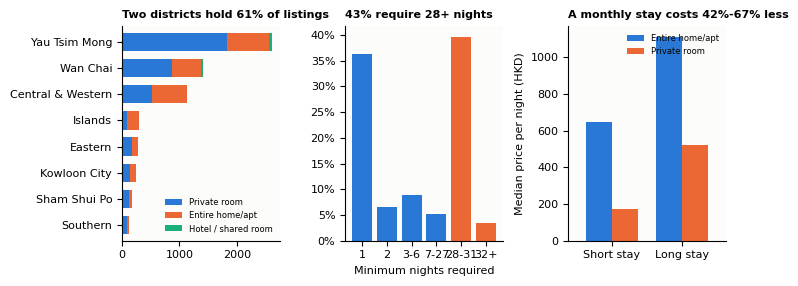

Hosts with 5+ listings own 73% of all listings (largest host: 344). Skewness of the price, raw -> log: 3.1 -> 0.41


In [5]:
# (a) listings per district and room type, (b) share of listings by minimum nights, (c) median price of short vs. monthly stays
rt3 = L.room_type.where(L.room_type.isin(["Private room", "Entire home/apt"]), "Hotel / shared room")
ct = pd.crosstab(L.neighbourhood_cleansed, rt3)[["Private room", "Entire home/apt", "Hotel / shared room"]]
by_district = ct.sum(axis=1).sort_values(ascending=False)
top2_share = by_district.head(2).sum() / len(L)
labels = ["1", "2", "3-6", "7-27", "28-31", "32+"]
mn_share = pd.cut(L.minimum_nights.dropna(), [0, 1, 2, 6, 27, 31, 10_000], labels=labels).value_counts(normalize=True).reindex(labels)
long_share = float((L.minimum_nights >= 28).mean())
med = df[df.room_type.isin(["Private room", "Entire home/apt"])].groupby(["room_type", "regime"]).price_hkd.median().unstack()
disc = 1 - med["Long stay (28+ nights)"] / med["Short stay (<28 nights)"]          # discount of a monthly stay

# Figure 1
fig, ax = plt.subplots(1, 3, figsize=(7.4, 2.9))
ct.loc[by_district.head(8).index].iloc[::-1].plot.barh(stacked=True, ax=ax[0], color=[PAL["blue"], PAL["orange"], PAL["aqua"]], width=0.7)
ax[0].set_title(f"Two districts hold {pct(top2_share)} of listings", fontsize=8); ax[0].set_ylabel(""); ax[0].legend(fontsize=6, loc="lower right")
ax[1].bar(labels, mn_share.values, color=[PAL["blue"]] * 4 + [PAL["orange"]] * 2)
ax[1].set_title(f"{pct(long_share)} require 28+ nights", fontsize=8); ax[1].set_xlabel("Minimum nights required"); ax[1].yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0))
med.T.plot.bar(ax=ax[2], color=[PAL["blue"], PAL["orange"]], width=0.75, rot=0)
ax[2].set_title(f"A monthly stay costs {pct(disc.min())}-{pct(disc.max())} less", fontsize=8); ax[2].set_xlabel(""); ax[2].set_ylabel("Median price per night (HKD)")
ax[2].set_xticklabels(["Short stay", "Long stay"]); ax[2].legend(fontsize=6)
fig.tight_layout()
savefig("fig1_market_overview", fig)

host_pro = float((L.calculated_host_listings_count >= 5).mean())   # share of listings that belong to hosts with 5+ listings
RESULTS["eda"] = dict(
    top2_share=float(top2_share), top2_names=list(by_district.head(2).index), long_stay_share=long_share,
    private_room_share=float((L.room_type == "Private room").mean()), entire_share=float((L.room_type == "Entire home/apt").mean()),
    median_price={f"{r}|{g}": float(med.loc[r, g]) for r in med.index for g in med.columns}, long_stay_discount={r: float(disc[r]) for r in disc.index},
    share_listings_from_hosts_5plus=host_pro, max_host_listings=int(L.calculated_host_listings_count.max()), n_hosts=int(L.host_id.nunique()),
    price_skew_raw=float(df.price_hkd.skew()), price_skew_log=float(np.log(df.price_hkd).skew()))
print(f"Hosts with 5+ listings own {pct(host_pro)} of all listings (largest host: {L.calculated_host_listings_count.max()}). "
      f"Skewness of the price, raw -> log: {df.price_hkd.skew():.1f} -> {np.log(df.price_hkd).skew():.2f}")

**Findings.**
* The market is **two markets**: short stays (typically tourists; the median nightly price is about 1.7× that of a monthly stay for whole homes and 3× for private rooms)
  and monthly rentals. *Stay policy is a first-class factor and the main segmentation of our analysis.*
* Supply is dominated by **private rooms** and by two districts, so the benchmark must be especially good there and honest about thin cells (outlying districts).
* Professional hosts (5+ listings) own most of the supply. This is a **leakage risk**: sister listings of one host look almost identical, so a random train/test split would
  overstate accuracy. We therefore split **by host** (section 8).
* Prices are very right-skewed (skewness ≈ 3, ≈ 0.4 after a log transform). We model **log-price**: errors become *percentage* errors, which is how a host thinks.

## 5. Enriching the data with geography (web data collection)
Inside Airbnb only gives the district and the coordinates of each listing. In Hong Kong the walk to an **MTR station** and the distance to the
main business and tourist hubs are what guests pay for, so we add this information ourselves: we download the location of every MTR station from
OpenStreetMap through its public **Overpass API** (`requests` + JSON), compute for every listing the distance to the nearest station and to
four hubs, and count how many other listings are nearby (local competition). The stations are saved in `data/mtr_stations.csv`, so the notebook runs offline.

In [6]:
def get_mtr_stations(cache=DATA / "mtr_stations.csv"):
    """MTR stations from the saved file, or from the OpenStreetMap API if the file does not exist yet."""
    if cache.exists():
        return pd.read_csv(cache)
    query = '[out:json][timeout:60];nwr["railway"="station"]["station"~"subway|train"](22.15,113.80,22.60,114.45);out center;'   # stations in a box around Hong Kong
    resp = requests.post("https://overpass-api.de/api/interpreter", data={"data": query}, headers={"User-Agent": "IS3240-student-project/1.0"}, timeout=120)
    resp.raise_for_status()
    rows = [dict(name=e["tags"].get("name:en") or e["tags"].get("name"), network=e["tags"].get("network"),
                 lat=e.get("lat") or e["center"]["lat"], lon=e.get("lon") or e["center"]["lon"]) for e in resp.json()["elements"]]
    st = pd.DataFrame(rows).dropna(subset=["name"])
    st = st[~st.network.fillna("").str.contains("Shenzhen|深圳")]                        # the box also contains Shenzhen stations: remove them
    st = st[~(st.network.isna() & (st.lat > 22.51)) & ~((st.lat > 22.45) & (st.lon < 114.0))]
    st = st.groupby("name", as_index=False).agg(lat=("lat", "mean"), lon=("lon", "mean"))
    st.to_csv(cache, index=False)
    return st

MTR = get_mtr_stations()
HUBS = {n: MTR.loc[MTR.name == n, ["lat", "lon"]].iloc[0].values for n in ["Central", "Tsim Sha Tsui", "Mong Kok", "Causeway Bay"]}   # the four main hubs

def haversine_km(lat1, lon1, lat2, lon2):
    """Straight-line distance in km between points given in degrees (works with NumPy arrays, so it can handle whole columns at once)."""
    p = np.pi / 180                                                # degrees -> radians
    a = np.sin((lat2 - lat1) * p / 2) ** 2 + np.cos(lat1 * p) * np.cos(lat2 * p) * np.sin((lon2 - lon1) * p / 2) ** 2
    return 2 * 6371 * np.arcsin(np.sqrt(a))                        # 6371 km = radius of the earth

def distance_features(lat, lon):
    """Distance features for arrays of coordinates: nearest MTR station, stations within 1 km, and distances to the hubs."""
    lat, lon = np.asarray(lat, dtype=float), np.asarray(lon, dtype=float)
    d = haversine_km(lat[:, None], lon[:, None], MTR.lat.values[None, :], MTR.lon.values[None, :])    # d[i, j] = distance from listing i to station j
    out = pd.DataFrame({"dist_mtr_km": d.min(axis=1), "n_mtr_1km": (d <= 1).sum(axis=1)})
    for name, col in [("Central", "dist_central_km"), ("Tsim Sha Tsui", "dist_tst_km")]:
        out[col] = haversine_km(lat, lon, *HUBS[name])
    out["dist_hub_min_km"] = np.minimum.reduce([haversine_km(lat, lon, *h) for h in HUBS.values()])   # nearest of the 4 hubs
    return out

GEO = distance_features(L.latitude, L.longitude)
GEO.index = L.index
# Local competition: number of OTHER listings within 500 m and 1 km (only locations are used, never prices)
lat_all, lon_all = L.latitude.values, L.longitude.values
n500, n1km = [], []
for la, lo in zip(lat_all, lon_all):
    d = haversine_km(la, lo, lat_all, lon_all)                     # distance from this listing to all listings
    n500.append((d <= 0.5).sum() - 1)                              # "- 1": the listing itself is not a competitor
    n1km.append((d <= 1.0).sum() - 1)
GEO["listings_500m"], GEO["listings_1km"] = n500, n1km

# Relative price = price / median price of listings with the same room type and stay type (1.2 = 20% above similar listings)
df = df.join(GEO)
df["price_rel"] = df.price_hkd / df.groupby(["room_type", "regime"]).price_hkd.transform("median")
df["mtr_band"] = pd.cut(df.dist_mtr_km, [0, 0.25, 0.5, 1.0, 2.0, 50], labels=["< 250 m", "250-500 m", "0.5-1 km", "1-2 km", "2+ km"])
bb = df.groupby("mtr_band").agg(rel=("price_rel", "median"), n=("price_rel", "size"))
RESULTS["geo"] = dict(n_stations=int(len(MTR)), median_dist_mtr_m=float(df.dist_mtr_km.median() * 1000), share_within_500m=float((df.dist_mtr_km <= 0.5).mean()),
                      band_rel_price={str(k): float(v) for k, v in bb.rel.items()}, band_n={str(k): int(v) for k, v in bb.n.items()})
display(bb.round(3))

,rel,n
mtr_band,,
< 250 m,0.990,2217
250-500 m,1.011,2252
0.5-1 km,1.017,547
1-2 km,1.056,138
2+ km,0.988,401


**Finding (partly negative).** There is **no simple "closer to the MTR = more expensive" gradient**: 40% of the listings are within 250 m of a station and half within 300 m,
because supply itself is located where the transit is. Location effects are entangled with *what kind of property* is offered, which is why a model that controls for
all factors at once, and not a chart of averages, is needed to separate them (sections 8 and 9).

### 5.1 Where is it expensive? A price map of Hong Kong
We map the asking price of **whole flats**, for short stays and for monthly stays. The colour scale is centred on the Hong Kong median (blue = cheaper, red = more expensive;
log scale). At every point of a fine grid we take the **median of the 18-22 nearest flats** (districts are too unequal and plain hexagon bins were too noisy) and we leave the map
blank where no flat is nearby.

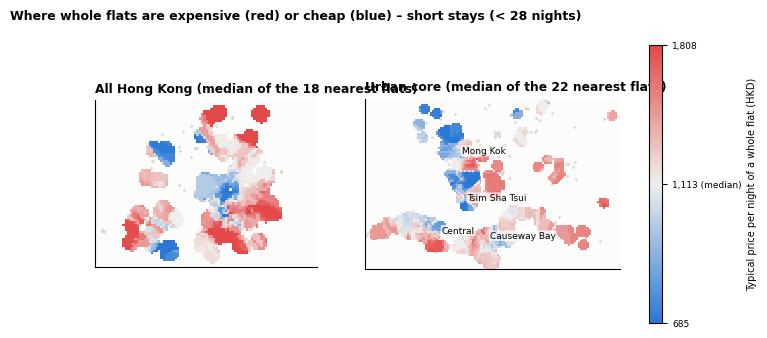

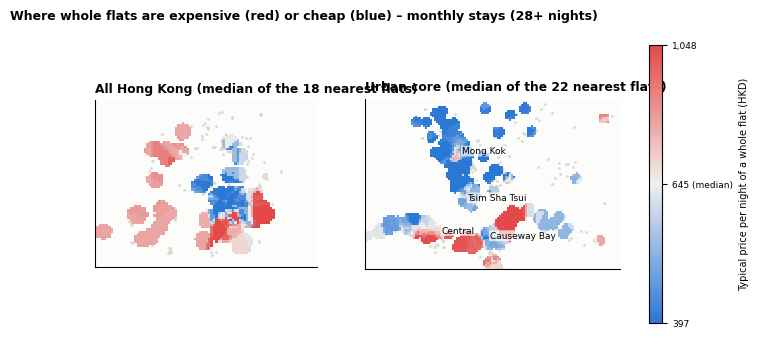

,median | monthly,median | short,size | monthly,size | short
neighbourhood_cleansed,,,,
North,NaN,3674.0,NaN,9.0
Southern,1601.0,3202.0,8.0,18.0
Kwun Tong,554.0,2464.0,2.0,6.0
Tai Po,730.0,1647.0,4.0,9.0
Sai Kung,1504.0,1570.0,4.0,17.0
Kowloon City,403.0,1500.0,14.0,29.0
Eastern,1168.0,1294.0,49.0,32.0
Wan Chai,833.0,1205.0,151.0,253.0
Central & Western,650.0,1153.0,137.0,301.0


In [7]:
from matplotlib.colors import LinearSegmentedColormap
blue_red = LinearSegmentedColormap.from_list("bluered", [PAL["blue"], "#f0efec", PAL["red"]])

def price_map(regime, title, name):
    """Map of the price of whole flats for one stay type: all Hong Kong (left) and the urban core (right)."""
    flats = df[(df.room_type == "Entire home/apt") & (df.regime == regime)]
    ref = flats.price_hkd.median()
    score = np.log2(flats.price_hkd.values / ref)                  # 0 = median, +1 = double the median, -1 = half the median
    fig, axes = plt.subplots(1, 2, figsize=(7.4, 3.6), gridspec_kw=dict(width_ratios=[1, 1.15]))
    for ax, (xlim, ylim, step, k, max_km, sub) in zip(axes, [((113.84, 114.40), (22.17, 22.56), 0.006, 18, 2.2, "All Hong Kong"),
                                                            ((114.12, 114.25), (22.265, 22.345), 0.001, 22, 0.3, "Urban core")]):
        gx, gy = np.meshgrid(np.arange(*xlim, step), np.arange(*ylim, step * 0.92))                  # grid of points
        d = haversine_km(gy.ravel()[:, None], gx.ravel()[:, None], flats.latitude.values[None, :], flats.longitude.values[None, :])   # grid points x flats
        z = np.median(score[np.argsort(d, axis=1)[:, :k]], axis=1)                                    # median score of the k nearest flats
        z[d.min(axis=1) > max_km] = np.nan                                                            # no colour where no flat is nearby
        ax.scatter(df.longitude, df.latitude, s=1, color="#d9d8d1", zorder=1)                         # grey dots: all listings (outline of the land)
        im = ax.pcolormesh(gx, gy, np.ma.masked_invalid(z.reshape(gx.shape)), cmap=blue_red, vmin=-0.7, vmax=0.7, zorder=2, rasterized=True)
        ax.set(xlim=xlim, ylim=ylim, xticks=[], yticks=[], aspect=1 / np.cos(np.radians(22.3)), title=f"{sub} (median of the {k} nearest flats)")
        ax.grid(False)
        if sub == "Urban core":
            for hub, (la, lo) in HUBS.items():
                ax.annotate(hub, (lo, la), fontsize=6.5, bbox=dict(boxstyle="round,pad=0.1", fc="white", ec="none", alpha=0.7))
    cb = fig.colorbar(im, ax=axes, fraction=0.035, ticks=[-0.7, 0, 0.7])
    cb.ax.set_yticklabels([f"{ref * 2 ** -0.7:,.0f}", f"{ref:,.0f} (median)", f"{ref * 2 ** 0.7:,.0f}"], fontsize=6.5)
    cb.set_label("Typical price per night of a whole flat (HKD)", fontsize=7)
    fig.suptitle(f"Where whole flats are expensive (red) or cheap (blue) – {title}", x=0.01, ha="left", fontsize=9, fontweight="bold")
    savefig(name, fig)
    return ref

ref_short = price_map("Short stay (<28 nights)", "short stays (< 28 nights)", "fig2b_price_map")
ref_long = price_map("Long stay (28+ nights)", "monthly stays (28+ nights)", "fig2c_price_map_monthly")

# Ranking of the districts: median price of a whole flat and number of flats behind each median
rank = df[df.room_type == "Entire home/apt"].groupby(["neighbourhood_cleansed", "regime"]).price_hkd.agg(["median", "size"]).unstack("regime")
rank.columns = [f"{a} | {'short' if 'Short' in b else 'monthly'}" for a, b in rank.columns]
rank = rank.sort_values("median | short", ascending=False)
big = rank[rank["size | short"] >= 30]                             # only districts with at least 30 short-stay flats are reliable
RESULTS["price_map"] = dict(ref_short=float(ref_short), ref_monthly=float(ref_long), most_expensive=big.index[0], cheapest=big.index[-1],
                            districts_ge30_short=[dict(district=i, median=float(r["median | short"]), n=int(r["size | short"])) for i, r in big.iterrows()])
display(rank.round(0))

**Finding.** The colour shows the *level* of the asking price of whole flats, not how good or profitable an area is: a red zone can simply contain larger flats, which is why
the models in the next sections control for size, type and stay before attributing a premium to location.

## 6. Useful factors: what could explain a listing's price, and why?
A model needs a table with one row per listing and one column per *factor* that might influence the price; this is where the business knowledge enters.
We organise the factors into **families**, each with a business rationale (hedonic pricing: a listing is a bundle of attributes that guests value). Grouping matters because
later we measure how much each *family* adds, which is a far more useful business statement than "feature 37 has importance 0.02".

| Family | Factors | Business rationale |
|---|---|---|
| **Property & capacity** | room type, property type, guests, bedrooms, beds, baths, shared bathroom | Space and privacy are what guests buy |
| **Stay policy & quote** | long stay (≥ 28 nights), log minimum nights, nights of the quoted stay, weekend check-in | Defines the customer (tourist vs. monthly renter). The scraped price is a *quote for a specific stay*, so the quote variables are **measurement controls**, set to a standard stay when benchmarking |
| **Location** | district, region, latitude/longitude | Neighbourhood prestige and demand |
| **Transit & centrality** | distance to the nearest MTR, MTR stations within 1 km, distance to Central / TST / nearest hub | Hong Kong is a transit city |
| **Local competition** | listings within 500 m and 1 km | More substitutes = price pressure (or a proven tourist area) |
| **Amenities** | 30 most common amenity flags + total count | Convenience that guests pay for |
| **Host profile** | professional host (5+ listings), host lives in Hong Kong | Professional operators price differently. Richer host variables (portfolio size, tenure...) did **not** help on unseen hosts, because they let a model recognise individual hosts |

*Deliberately excluded:* the quote's **lead time** (days until the quoted check-in) is partly an *outcome* of demand (busy listings are booked up), so it would leak demand into price.
**Ratings and review activity** exist only after a listing has guests; a new host has none, so they are **not** used by the benchmark for new listings (only in a separate model, section 11).

In [8]:
# Simplify categories with too many values (rare categories only add noise); we only use counts here, never the price
ptype_counts = df.property_type.value_counts()
TOP_PTYPES = ptype_counts[ptype_counts >= 50].index.tolist()          # property types with at least 50 listings; the rest become "Other"
dist_counts = df.neighbourhood_cleansed.value_counts()
KEEP_DISTRICTS = dist_counts[dist_counts >= 60].index.tolist()        # districts with at least 60 listings; the rest become "Other districts"
REGION = {d: "Hong Kong Island" for d in ["Central & Western", "Wan Chai", "Eastern", "Southern"]}
REGION.update({d: "Kowloon" for d in ["Yau Tsim Mong", "Sham Shui Po", "Kowloon City", "Wong Tai Sin", "Kwun Tong"]})   # all others: New Territories & Islands

# Amenities are stored as one text per listing that looks like a Python list: '["Wifi", "Kitchen", ...]'
def parse_list(s):
    try:
        return json.loads(s)
    except Exception:
        return []

amen_lists = L.amenities.apply(parse_list)
amen_prev = pd.Series([a for lst in amen_lists.loc[df.index] for a in lst]).value_counts() / len(df)      # share of listings that offer each amenity
AMEN = amen_prev[(amen_prev >= 0.05) & (amen_prev <= 0.97)].head(30).index.tolist()                       # 30 most common, neither universal nor rare
AMEN_COLS = {a: "am_" + re.sub(r"[^a-z0-9]+", "_", a.lower()).strip("_") for a in AMEN}                   # amenity name -> column name
print(f"{len(TOP_PTYPES)} property types and {len(KEEP_DISTRICTS)} districts kept; {len(amen_prev)} distinct amenities, {len(AMEN)} flagged: {AMEN[:6]} ...")

11 property types and 9 districts kept; 835 distinct amenities, 30 flagged: ['Wifi', 'Air conditioning', 'Kitchen', 'Hot water', 'Hangers', 'Hair dryer'] ...


In [9]:
# The factor table: one small block per family
X_all = pd.DataFrame(index=df.index)
X_all["room_type"] = df.room_type
X_all["property_type_grp"] = df.property_type.where(df.property_type.isin(TOP_PTYPES), "Other")
X_all["accommodates"], X_all["bedrooms"], X_all["beds"] = df.accommodates, df.bedrooms, df.beds
X_all["studio"] = (df.bedrooms == 0).astype(int)                                       # 0 bedrooms = studio
bath_text = df.bathrooms_text.fillna("").str.lower()                                   # e.g. "1.5 baths", "1 shared bath", "Shared half-bath"
X_all["baths"] = bath_text.str.extract(r"(\d+(?:\.\d+)?)")[0].astype(float)            # the number in the text (regular expression)
X_all.loc[bath_text.str.contains("half") & X_all.baths.isna(), "baths"] = 0.5          # a "half-bath" without number counts as 0.5
X_all["bath_shared"] = bath_text.str.contains("shared").astype(int)

X_all["long_stay"] = df.long_stay
X_all["log_min_nights"] = np.log(df.minimum_nights.clip(lower=1))
q_in, q_out = pd.to_datetime(df.price_quote_checkin_date), pd.to_datetime(df.price_quote_checkout_date)   # the quoted stay
q_nights = (q_out - q_in).dt.days
X_all["q_log_nights"] = np.log(q_nights.where(q_nights >= 1, df.minimum_nights).clip(lower=1))            # if unknown, use the minimum nights
X_all["q_weekend"] = q_in.dt.dayofweek.isin([4, 5]).astype(int)                        # Friday or Saturday check-in

X_all["district_grp"] = df.neighbourhood_cleansed.where(df.neighbourhood_cleansed.isin(KEEP_DISTRICTS), "Other districts")
X_all["region"] = df.neighbourhood_cleansed.map(REGION).fillna("New Territories & Islands")
X_all["lat"], X_all["lon"] = df.latitude, df.longitude

transit_cols = ["dist_mtr_km", "n_mtr_1km", "dist_central_km", "dist_tst_km", "dist_hub_min_km", "listings_500m", "listings_1km"]   # computed in section 5
X_all[transit_cols] = df[transit_cols]
for amenity, col in AMEN_COLS.items():
    X_all[col] = amen_lists.loc[df.index].apply(lambda lst: int(amenity in lst))       # 1 if the listing offers the amenity
X_all["n_amenities"] = amen_lists.loc[df.index].apply(len)

X_all["pro_host"] = (df.calculated_host_listings_count >= 5).astype(int)               # professional operator: 5+ listings
X_all["host_local"] = df.host_location.fillna("").str.contains("Hong Kong").astype(int)

CAT_COLS = ["room_type", "property_type_grp", "district_grp", "region"]               # columns that contain categories (text)
FAMILIES = {
    "Property & capacity": ["room_type", "property_type_grp", "accommodates", "bedrooms", "studio", "beds", "baths", "bath_shared"],
    "Stay policy & quote": ["long_stay", "log_min_nights", "q_log_nights", "q_weekend"],
    "Location": ["district_grp", "region", "lat", "lon"],
    "Transit & centrality": ["dist_mtr_km", "n_mtr_1km", "dist_central_km", "dist_tst_km", "dist_hub_min_km"],
    "Local competition": ["listings_500m", "listings_1km"],
    "Amenities": list(AMEN_COLS.values()) + ["n_amenities"],
    "Host profile": ["pro_host", "host_local"]}
NEW_COLS = [c for cols in FAMILIES.values() for c in cols]                            # all launch-time factors
assert set(NEW_COLS) == set(X_all.columns)                                            # check: the families cover exactly the columns of the table
RESULTS["features"] = dict(families={k: len(v) for k, v in FAMILIES.items()}, n_total=len(NEW_COLS), amenities_flagged=AMEN,
                           top_property_types=TOP_PTYPES, kept_districts=KEEP_DISTRICTS)
print({k: len(v) for k, v in FAMILIES.items()}, "-> total", len(NEW_COLS), "launch-time factors")
print("Missing values:", X_all.isna().sum()[lambda s: s > 0].to_dict(), "(filled with the training median before modelling)")

# Experience factors (only for listings that already have guests): ratings and review activity
RATING_COLS = ["accuracy", "cleanliness", "checkin", "communication", "location", "value", "rating"]
EXP_ALL = pd.DataFrame({f"rs_{c}": df[f"review_scores_{c}"] for c in RATING_COLS}, index=df.index)
EXP_ALL["log_n_reviews"] = np.log1p(df.number_of_reviews)
EXP_ALL["reviews_ltm"] = df.number_of_reviews_ltm                                     # reviews in the last 12 months
EXP_ALL["reviews_per_month"] = df.reviews_per_month
EXP_ALL["days_since_last_review"] = (SCRAPE_DATE - df.last_review).dt.days
EXP_ALL["superhost"] = (df.host_is_superhost == "t").astype(int)
EXP_ALL["has_reviews"] = (df.number_of_reviews > 0).astype(int)
EXP_FAMILIES = {"Reviews & ratings": list(EXP_ALL.columns)}

{'Property & capacity': 8, 'Stay policy & quote': 4, 'Location': 4, 'Transit & centrality': 5, 'Local competition': 2, 'Amenities': 31, 'Host profile': 2} -> total 56 launch-time factors
Missing values: {'bedrooms': 19, 'beds': 97, 'baths': 19} (filled with the training median before modelling)


## 7. Market segments – unsupervised learning (KMeans + PCA)
*Business question:* which kinds of listings really exist in this market, and do they behave differently on price? If there are a few distinct *segments*, a host should
benchmark against their own segment. **Price is deliberately NOT an input**: we cluster on the characteristics of the offer (size, room type, stay policy, centrality, operator
type, amenities, local density), so that price differences between segments are a *finding*. The inputs are standardised (KMeans is distance-based). We choose the number of
clusters *k* with the silhouette score, but only among **k = 4…7** and only if **every segment holds at least 3% of the listings** (a segment of 28 listings is not a market).

silhouette: {3: 0.217, 4: 0.224, 5: 0.231, 6: 0.231, 7: 0.237, 8: 0.248} -> chosen k = 5


,n,median_price,entire,long_stay,guests,bedrooms,dist_central,shared_bath,pro_host,label
seg_id,,,,,,,,,,
1,1752,174.42,0.01,0.97,1.0,1.0,3.03,0.50,0.98,"Private rooms, monthly"
0,1645,500.00,0.00,0.04,2.0,1.0,2.73,0.27,0.83,"Private rooms, short-stay"
4,1178,739.50,1.00,0.37,2.0,1.0,2.60,0.00,0.61,"Whole units, mixed stay"
2,414,786.52,0.53,0.16,2.0,1.0,15.63,0.24,0.25,"Mixed units, short-stay, outer areas"
3,566,1469.80,0.93,0.16,7.0,2.0,2.93,0.02,0.55,"Whole units, short-stay, groups"


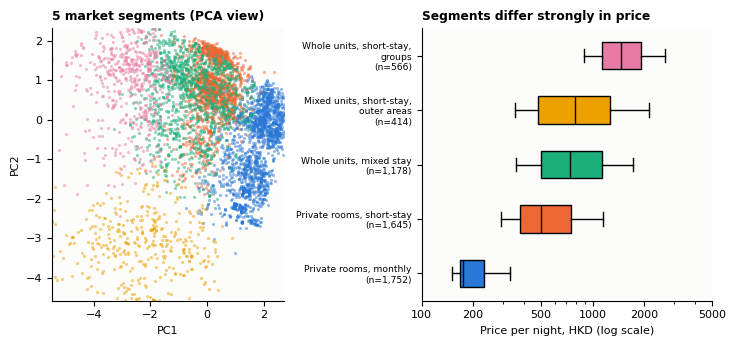

In [10]:
seg_in = pd.DataFrame({
    "accommodates": X_all.accommodates, "bedrooms": X_all.bedrooms.fillna(1), "baths": X_all.baths.fillna(1), "bath_shared": X_all.bath_shared,
    "is_entire": (X_all.room_type == "Entire home/apt").astype(int), "log_min_nights": X_all.log_min_nights,
    "log_dist_central": np.log1p(X_all.dist_central_km), "log_dist_mtr": np.log1p(X_all.dist_mtr_km),
    "host_listings": np.log1p(df.calculated_host_listings_count), "n_amenities": X_all.n_amenities, "listings_500m": X_all.listings_500m})
Z = StandardScaler().fit_transform(seg_in)                          # every column: mean 0, standard deviation 1

# Which k? Silhouette score (higher = better separated groups) and share of the smallest group, for k = 3..8
sil, smallest = {}, {}
for k in range(3, 9):
    labels_k = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(Z).labels_
    sil[k] = silhouette_score(Z, labels_k, sample_size=3000, random_state=SEED)
    smallest[k] = np.bincount(labels_k).min() / len(Z)
K_SEG = max([k for k in range(4, 8) if smallest[k] >= 0.03], key=lambda k: sil[k])     # best silhouette among the eligible k
print("silhouette:", {k: round(v, 3) for k, v in sil.items()}, "-> chosen k =", K_SEG)
df["seg_id"] = KMeans(n_clusters=K_SEG, n_init=20, random_state=SEED).fit(Z).labels_

# Describe each segment (one row per segment) and name it from its typical characteristics
prof = df.assign(entire=X_all.room_type.eq("Entire home/apt"), long=X_all.long_stay, acc=X_all.accommodates, bed=X_all.bedrooms,
                 dc=X_all.dist_central_km, shared=X_all.bath_shared, pro=X_all.pro_host).groupby("seg_id").agg(
    n=("price_hkd", "size"), median_price=("price_hkd", "median"), entire=("entire", "mean"), long_stay=("long", "mean"), guests=("acc", "median"),
    bedrooms=("bed", "median"), dist_central=("dc", "median"), shared_bath=("shared", "mean"), pro_host=("pro", "mean"))

def label_segment(r):
    room = "Whole units" if r.entire > 0.6 else ("Private rooms" if r.entire < 0.25 else "Mixed units")
    stay = "monthly" if r.long_stay > 0.65 else ("short-stay" if r.long_stay < 0.35 else "mixed stay")
    extra = ", groups" if r.guests >= 4 else (", outer areas" if r.dist_central > 7 else "")
    return f"{room}, {stay}{extra}"

prof["label"] = prof.apply(label_segment, axis=1)
prof = prof.sort_values("median_price")
df["segment"] = df.seg_id.map(prof.label)
display(prof.round(2))

# Figure 3: left = segments seen through PCA (11 columns reduced to 2), right = price distribution of each segment
P = PCA(n_components=2, random_state=SEED).fit_transform(Z)
fig, ax = plt.subplots(1, 2, figsize=(7.4, 3.5), gridspec_kw=dict(width_ratios=[1, 1.25]))
for i, sid in enumerate(prof.index):
    m = df.seg_id.values == sid
    ax[0].scatter(P[m, 0], P[m, 1], s=5, alpha=0.5, color=CAT[i], linewidths=0)
ax[0].set(xlim=np.percentile(P[:, 0], [0.5, 99.5]), ylim=np.percentile(P[:, 1], [0.5, 99.5]), xlabel="PC1", ylabel="PC2", title=f"{K_SEG} market segments (PCA view)")
bp = ax[1].boxplot([df.loc[df.seg_id == sid, "price_hkd"] for sid in prof.index], vert=False, patch_artist=True, showfliers=False, whis=(10, 90),
                   medianprops=dict(color=PAL["ink"]))
for patch, color in zip(bp["boxes"], CAT):
    patch.set_facecolor(color)
ax[1].set_xscale("log"); ax[1].set_xticks([100, 200, 500, 1000, 2000, 5000]); ax[1].get_xaxis().set_major_formatter(mpl.ticker.ScalarFormatter())
ax[1].set_yticklabels([textwrap.fill(prof.loc[s, "label"], 26) + f"\n(n={int(prof.loc[s, 'n']):,})" for s in prof.index], fontsize=6.6)
ax[1].set(xlabel="Price per night, HKD (log scale)", title="Segments differ strongly in price")
fig.tight_layout()
savefig("fig3_segments", fig)
RESULTS["segments"] = dict(k=K_SEG, silhouette={int(k): float(v) for k, v in sil.items()},
                           profile=[dict(label=r.label, n=int(r.n), share=float(r.n / len(df)), median_price=float(r.median_price), entire=float(r.entire),
                                         long_stay=float(r.long_stay), guests=float(r.guests), bedrooms=float(r.bedrooms),
                                         dist_central=float(r.dist_central), pro_host=float(r.pro_host)) for _, r in prof.iterrows()])

**Finding.** The market splits into a few clearly different segments whose **median prices differ by almost an order of magnitude**, although price was *not* used to build them.
The biggest segment is single-guest rooms rented by the month, mostly by professional hosts; whole flats for groups sit at the other end. Practical rule: **compare a listing only with its own segment**.

## 8. Supervised learning: a benchmark that is *honest* for a real user
**Target:** `log(price per night)`: errors read as percentages ("20% above market") and a few very expensive listings do not dominate the fit. Results are reported in HKD.

**Three decisions protect the credibility of the result:**
1. **Split by host, not by listing.** A professional host with 40 near-identical listings would otherwise appear in both train and test and the model
   would be rewarded for memorising the host. All listings of a host go to the same side (`GroupShuffleSplit`, 80/20); cross-validation also keeps hosts together (`GroupKFold`).
2. **Everything that is "learned" from data uses the training part only** (the median that fills missing values, the settings of the models).
3. **The model is chosen with cross-validation on the training data**; the test set is used once, to report the final performance.

**Models:** the *comparable-listings baseline* (what hosts do today: median price of listings in the same district, room type and stay type), **linear regression**
(simple and transparent), **random forest** and **gradient boosting** (non-linear effects and interactions without hand-made terms).
**Metrics:** MAE in HKD, median absolute % error, share of listings predicted within ±20%, and RMSE and R² (on log prices).

In [11]:
X = pd.get_dummies(X_all, columns=CAT_COLS, dtype=int)         # predictors: categories become 0/1 columns (one-hot encoding)
y = np.log(df.price_hkd.values)                                # target: log price
groups = df.host_id.values                                     # the host of every listing

# Train/test split by host (80/20). One random split can be unbalanced because a few hosts own hundreds of listings (one: 344), so we try 50 random
# splits and keep the one whose test set is closest to the whole sample (share of monthly stays, median price, size). No model result is used for this.
def imbalance(test_rows):
    return (abs(X_all.long_stay.iloc[test_rows].mean() - X_all.long_stay.mean()) + abs(np.median(y[test_rows]) - np.median(y)) + abs(len(test_rows) / len(y) - 0.2))

splits = {s: next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=s).split(X, y, groups)) for s in range(50)}
SPLIT_SEED = min(splits, key=lambda s: imbalance(splits[s][1]))
train_idx, test_idx = splits[SPLIT_SEED]
assert not set(groups[train_idx]) & set(groups[test_idx]), "a host appears in both train and test!"

train_median = X.iloc[train_idx].median()
X = X.fillna(train_median)                                     # missing values -> median of the TRAINING rows
X_train, X_test, y_train, y_test = X.iloc[train_idx], X.iloc[test_idx], y[train_idx], y[test_idx]
g_train = groups[train_idx]
p_train, p_test = np.exp(y_train), np.exp(y_test)              # prices in HKD (exp undoes the log)
print(f"split seed {SPLIT_SEED}: train {len(train_idx):,} listings / {len(set(g_train)):,} hosts | test {len(test_idx):,} listings / {len(set(groups[test_idx])):,} hosts")
print("monthly-stay share train vs test:", pct(X_all.long_stay.iloc[train_idx].mean()), "vs", pct(X_all.long_stay.iloc[test_idx].mean()))
RESULTS["split"] = dict(seed=int(SPLIT_SEED), n_train=len(train_idx), n_test=len(test_idx), hosts_train=len(set(g_train)),
                        hosts_test=len(set(groups[test_idx])), test_size=0.2, cv_folds=5)

def evaluate(p_true, p_pred):
    """Accuracy measures from real and predicted prices (HKD)."""
    err = np.abs(p_pred - p_true) / p_true                     # absolute percentage error of each prediction
    return dict(MAE=float(mean_absolute_error(p_true, p_pred)), RMSE=float(np.sqrt(np.mean((p_pred - p_true) ** 2))),
                R2_log=float(r2_score(np.log(p_true), np.log(p_pred))), MedAPE=float(np.median(err)), Within20=float(np.mean(err <= 0.20)))

def comparable_price(train_rows, test_rows):
    """The benchmark to beat: median price of the comparable listings of the training data (same district, room type and stay type);
    with fewer than 5 comparables: median of the same room type and stay type."""
    keys = ["district_grp", "room_type", "long_stay"]
    train = X_all.iloc[train_rows][keys].assign(price=np.exp(y[train_rows]))
    fine = train.groupby(keys).price.agg(["median", "size"]).query("size >= 5")["median"].rename("fine")
    coarse = train.groupby(["room_type", "long_stay"]).price.median().rename("coarse")
    pred = X_all.iloc[test_rows][keys].join(fine, on=keys).join(coarse, on=["room_type", "long_stay"])
    return pred.fine.fillna(pred.coarse).fillna(train.price.median()).values

split seed 37: train 4,437 listings / 940 hosts | test 1,118 listings / 235 hosts
monthly-stay share train vs test: 42% vs 44%


**Training.** Random forest and gradient boosting have settings (e.g. the depth of the trees). We choose them with a small grid search: every combination is
evaluated with 5-fold cross-validation on the training data (folds keep each host's listings together) and the best one is kept. The error used is the MAE of the log price.

In [12]:
cv = GroupKFold(n_splits=5)
def tune(model, grid):
    """Grid search with host-grouped 5-fold cross-validation on the training data."""
    return GridSearchCV(model, grid, cv=cv, scoring="neg_mean_absolute_error", n_jobs=-1).fit(X_train, y_train, groups=g_train)

linear = LinearRegression().fit(X_train, y_train)
rf = tune(RandomForestRegressor(n_estimators=200, random_state=SEED), {"max_depth": [10, 20], "min_samples_leaf": [2, 5], "max_features": [0.3, 0.6]})
gb = tune(GradientBoostingRegressor(random_state=SEED), {"n_estimators": [150, 300], "learning_rate": [0.05, 0.1], "max_depth": [3, 5]})
models = {"Linear regression": linear, "Random forest": rf.best_estimator_, "Gradient boosting": gb.best_estimator_}
best_params = {"Linear regression": {}, "Random forest": rf.best_params_, "Gradient boosting": gb.best_params_}
cv_mae = {"Linear regression": -cross_val_score(LinearRegression(), X_train, y_train, cv=cv, groups=g_train, scoring="neg_mean_absolute_error").mean(),
          "Random forest": -rf.best_score_, "Gradient boosting": -gb.best_score_}
BEST = min(cv_mae, key=cv_mae.get)                             # chosen by cross-validation, never by the test score
print("CV error (MAE of the log price):", {k: round(v, 3) for k, v in cv_mae.items()}, "-> selected:", BEST)

CV error (MAE of the log price): {'Linear regression': 0.373, 'Random forest': 0.327, 'Gradient boosting': 0.323} -> selected: Gradient boosting


**The final exam: the test set (used once).** We predict the 20% of listings that the models have never seen and compare with the real prices and with the two baselines.

In [13]:
preds = {"Global median": np.full(len(test_idx), np.median(p_train)),            # naive: everyone gets the overall median
         "Comparable-listings baseline": comparable_price(train_idx, test_idx)}  # what hosts do today
for name, model in models.items():
    preds[name] = np.exp(model.predict(X_test))                # exp: back from log price to HKD
results = pd.DataFrame({name: evaluate(p_test, p) for name, p in preds.items()}).T
results["CV MAE (log)"] = pd.Series(cv_mae)
display(results.round(3))
base_mae, best_mae = results.loc["Comparable-listings baseline", "MAE"], results.loc[BEST, "MAE"]
print(f"MAE: baseline {base_mae:.0f} HKD -> {BEST} {best_mae:.0f} HKD ({pct(1 - best_mae / base_mae)} lower)")

# How sure are we of the improvement? Bootstrap over HOSTS (a host's listings are not independent): add up the errors of each host, resample the hosts
# with replacement 2,000 times and recompute the improvement; the 2.5th and 97.5th percentiles give a 95% interval.
host_err = pd.DataFrame({"host": groups[test_idx], "baseline": np.abs(preds["Comparable-listings baseline"] - p_test), "best": np.abs(preds[BEST] - p_test)}).groupby("host").sum()
rng = np.random.default_rng(SEED)
gains = []
for _ in range(2000):
    s = host_err.sample(frac=1, replace=True, random_state=int(rng.integers(1_000_000_000)))
    gains.append(1 - s.best.sum() / s.baseline.sum())
ci = np.percentile(gains, [2.5, 97.5])
print(f"95% host-bootstrap interval of the improvement: {pct(ci[0], 1)} to {pct(ci[1], 1)}")

# Accuracy of the selected model by group (test set)
def error_by(group):
    d = pd.DataFrame({"group": np.asarray(group), "real": p_test, "pred": preds[BEST]})
    rows = {}
    for g, s in d.groupby("group"):
        e = evaluate(s.real.values, s.pred.values)
        rows[g] = dict(n=len(s), median_price=s.real.median(), MAE=e["MAE"], MedAPE=e["MedAPE"], Within20=e["Within20"])
    return pd.DataFrame(rows).T

room = X_all.room_type.iloc[test_idx].where(X_all.room_type.iloc[test_idx].isin(["Private room", "Entire home/apt"]), "Other")
stay = np.where(X_all.long_stay.iloc[test_idx] == 1, "long stay", "short stay")
by_room_stay = error_by(room.values + " | " + stay)
by_segment = error_by(df.segment.iloc[test_idx].values).sort_values("median_price")      # segments of section 7
display(by_room_stay.round(3)); display(by_segment.round(3))

RESULTS["models"] = dict(table={k: {m: float(v) for m, v in r.items() if pd.notna(v)} for k, r in results.iterrows()}, best=BEST, best_params=best_params,
                         mae_reduction=float(1 - best_mae / base_mae), mae_reduction_ci=[float(ci[0]), float(ci[1])], cv_mae_log={k: float(v) for k, v in cv_mae.items()},
                         by_regime_room={k: r.to_dict() for k, r in by_room_stay.iterrows()}, by_segment={k: r.to_dict() for k, r in by_segment.iterrows()})

,MAE,RMSE,R2_log,MedAPE,Within20,CV MAE (log)
Global median,533.623,889.868,-0.006,0.687,0.148,NaN
Comparable-listings baseline,365.521,734.661,0.565,0.236,0.456,NaN
Linear regression,325.750,651.067,0.725,0.260,0.403,0.373
Random forest,273.014,582.066,0.796,0.184,0.533,0.327
Gradient boosting,267.035,562.508,0.802,0.198,0.505,0.323


MAE: baseline 366 HKD -> Gradient boosting 267 HKD (27% lower)


95% host-bootstrap interval of the improvement: 20.0% to 33.1%


,n,median_price,MAE,MedAPE,Within20
Entire home/apt | long stay,65.0,616.150,206.156,0.228,0.400
Entire home/apt | short stay,277.0,1255.000,439.508,0.226,0.440
Other | long stay,4.0,125.515,44.835,0.511,0.500
Other | short stay,13.0,475.000,169.353,0.292,0.231
Private room | long stay,425.0,178.300,55.186,0.103,0.687
Private room | short stay,334.0,589.165,411.875,0.313,0.359


,n,median_price,MAE,MedAPE,Within20
"Private rooms, monthly",418.0,177.330,38.501,0.101,0.701
"Private rooms, short-stay",293.0,580.000,388.106,0.294,0.358
"Mixed units, short-stay, outer areas",93.0,700.000,494.593,0.347,0.301
"Whole units, mixed stay",168.0,796.490,294.698,0.243,0.435
"Whole units, short-stay, groups",146.0,1582.095,501.576,0.213,0.452


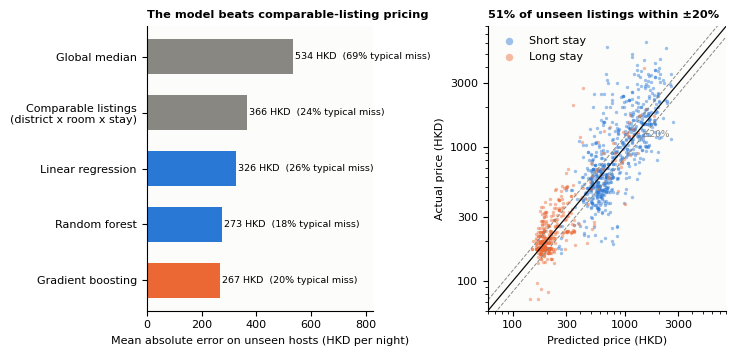

In [14]:
# Figure 4: left = error of every method, right = predicted vs. real price of the selected model
order = ["Global median", "Comparable-listings baseline", "Linear regression", "Random forest", "Gradient boosting"]
fig, ax = plt.subplots(1, 2, figsize=(7.4, 3.6), gridspec_kw=dict(width_ratios=[1, 1.05]))
a = ax[0]
vals = [results.loc[o, "MAE"] for o in order]
colors = [PAL["muted"] if o in order[:2] else (PAL["orange"] if o == BEST else PAL["blue"]) for o in order]     # grey = baselines, orange = selected model
a.barh([o.replace("Comparable-listings baseline", "Comparable listings\n(district x room x stay)") for o in order][::-1], vals[::-1], color=colors[::-1], height=0.62)
for i, (o, v) in enumerate(zip(order[::-1], vals[::-1])):
    a.text(v + 8, i, f"{v:,.0f} HKD  ({pct(results.loc[o, 'MedAPE'])} typical miss)", va="center", fontsize=6.8)
a.set_xlim(0, max(vals) * 1.55); a.set_xlabel("Mean absolute error on unseen hosts (HKD per night)"); a.grid(axis="y", visible=False)
a.set_title("The model beats comparable-listing pricing", fontsize=8.2)
b = ax[1]
is_long = X_all.long_stay.iloc[test_idx].values == 1
for flag, col, lab in [(False, PAL["blue"], "Short stay"), (True, PAL["orange"], "Long stay")]:
    b.scatter(preds[BEST][is_long == flag], p_test[is_long == flag], s=6, alpha=0.45, color=col, linewidths=0, label=lab)     # each dot = one unseen listing
lim = np.array([60, 8000])
b.plot(lim, lim, color=PAL["ink"], lw=0.9)                                                                      # perfect prediction
b.plot(lim, lim * 1.2, color=PAL["muted"], lw=0.7, ls="--"); b.plot(lim, lim / 1.2, color=PAL["muted"], lw=0.7, ls="--")   # +-20%
b.set_xscale("log"); b.set_yscale("log"); b.set_xlim(lim); b.set_ylim(lim); b.set_xticks([100, 300, 1000, 3000]); b.set_yticks([100, 300, 1000, 3000])
b.get_xaxis().set_major_formatter(mpl.ticker.ScalarFormatter()); b.get_yaxis().set_major_formatter(mpl.ticker.ScalarFormatter())
b.set_xlabel("Predicted price (HKD)"); b.set_ylabel("Actual price (HKD)"); b.legend(loc="upper left", markerscale=2.2)
b.text(2500, 2000 / 1.25 * 0.74, "±20%", fontsize=6.5, color=PAL["muted"], ha="right")
b.set_title(f"{pct(results.loc[BEST, 'Within20'])} of unseen listings within ±20%", fontsize=8.2)
fig.tight_layout(w_pad=1.2)
savefig("fig4_model_performance", fig)

**Finding.** The best machine-learning model reduces the typical error by about a fifth or more compared with what a host does today, and the improvement is not luck
(the bootstrap interval stays well above zero). The points in the right-hand chart follow the diagonal but are far from perfect, which is realistic: asking prices
are noisy. That is why the benchmark always comes with a **price band** (section 12).

## 9. What drives the price? Importance of each factor family
A host or manager wants to know **which information really matters**. We use *permutation importance*, an explainability method that is easy to state: take the selected model,
**scramble one family of factors** (for example all location columns) among the test listings, and see how much worse the predictions become. If scrambling a family hardly
changes the error, the model does not need it; if the error jumps, the family is important. We use the **test hosts** (never seen in training), scramble every family 5 times
and report the increase in the typical (median) percentage error, in percentage points.

Typical error of the Gradient boosting model on test hosts: 19.8%


,family,increase_pts,n_columns
0,Property & capacity,21.44,22
1,Stay policy & quote,16.91,4
5,Amenities,10.45,31
6,Host profile,1.59,2
2,Location,1.04,15
4,Local competition,0.61,2
3,Transit & centrality,0.42,5


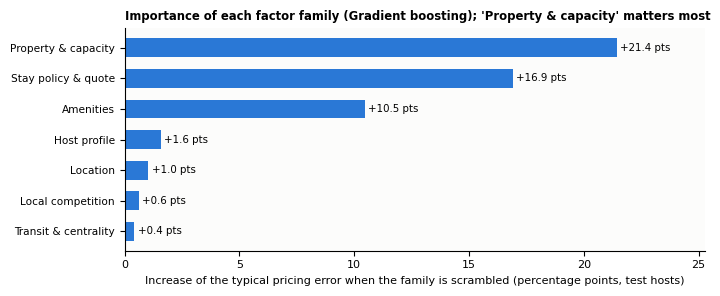

In [15]:
def family_columns(factors):
    """Columns of the model table X that belong to the given factors (a category became several 0/1 columns)."""
    return [c for c in X.columns if c in factors or any(c.startswith(f + "_") for f in factors if f in CAT_COLS)]

rng = np.random.default_rng(SEED)
model_best = models[BEST]
error_normal = evaluate(p_test, np.exp(model_best.predict(X_test)))["MedAPE"]        # typical error without scrambling
rows = []
for family, factors in FAMILIES.items():
    cols = family_columns(factors)
    increases = []
    for repetition in range(5):
        X_scrambled = X_test.copy()
        X_scrambled[cols] = X_test[cols].values[rng.permutation(len(X_test))]        # shuffle the rows of this family together
        increases.append(evaluate(p_test, np.exp(model_best.predict(X_scrambled)))["MedAPE"] - error_normal)
    rows.append(dict(family=family, increase_pts=100 * np.mean(increases), n_columns=len(cols)))
imp = pd.DataFrame(rows).sort_values("increase_pts", ascending=False)
print(f"Typical error of the {BEST} model on test hosts: {pct(error_normal, 1)}")
display(imp.round(2))
RESULTS["importance"] = dict(base_error=float(error_normal), table=imp.to_dict(orient="records"))

# Figure 5: one bar per family
fig, ax = plt.subplots(figsize=(7.2, 3.0))
ypos = np.arange(len(imp))[::-1]
ax.barh(ypos, imp.increase_pts, color=PAL["blue"], height=0.62)
ax.set_yticks(ypos); ax.set_yticklabels(imp.family, fontsize=7.6); ax.grid(axis="y", visible=False)
for y_, v in zip(ypos, imp.increase_pts):
    ax.text(v + 0.15, y_, f"+{v:.1f} pts", va="center", fontsize=7.4)
ax.set_xlim(0, imp.increase_pts.max() * 1.18)
ax.set_xlabel("Increase of the typical pricing error when the family is scrambled (percentage points, test hosts)")
ax.set_title(f"Importance of each factor family ({BEST}); '{imp.family.iloc[0]}' matters most", fontsize=8.4)
fig.tight_layout()
savefig("fig5_importance", fig)

**Finding.** The **property** (room type, size) and the **stay policy** (short stay or monthly) are the most important families: scrambling them makes the benchmark much worse.
Amenities come third mostly because they mark the *type* of listing. Location, competition, host flags and **transit distance add very little** once the property and the stay are known.
Caution: importance says what the model *uses*, not what *causes* the price; and correlated factors (for instance district and distance to Central) can share importance.

## 10. From prediction to action: who is priced away from the benchmark, and does it cost them guests?
A prediction is only useful if it changes a decision. We use the benchmark as a **price audit**:
1. for *every* listing we take the prediction of a model that has never seen that host (5-fold cross-validation grouped by host);
2. **price gap** = real price ÷ benchmark − 1; a listing is *above benchmark* if it is ≥ 25% above, *below benchmark* if ≥ 20% below (the same ±25% band on a ratio scale);
3. we ask what a host cares about: **do listings priced above the benchmark attract fewer guests?** We use the number of reviews in the last 12 months as a demand proxy
   (reviews are a roughly constant fraction of stays).

In [16]:
p_all = df.price_hkd.values                                  # real prices (HKD)
# Predictions for all listings from models that never saw the listing's host, for the selected model and for the baseline
folds = GroupKFold(n_splits=5)
oof = cross_val_predict(clone(models[BEST]), X, y, cv=folds, groups=groups, n_jobs=-1)       # predicted log price
oof_base = np.zeros(len(df))
for rows_train, rows_test in folds.split(X, y, groups):
    oof_base[rows_test] = comparable_price(rows_train, rows_test)
m_oof, m_base = evaluate(p_all, np.exp(oof)), evaluate(p_all, oof_base)
print(f"All {len(df):,} listings, host-grouped 5-fold CV: {BEST} MAE {m_oof['MAE']:.0f} HKD, typical error {pct(m_oof['MedAPE'], 1)}, within ±20%: {pct(m_oof['Within20'])} | "
      f"baseline MAE {m_base['MAE']:.0f} HKD, typical error {pct(m_base['MedAPE'], 1)}")
RESULTS["oof"] = dict(model=m_oof, baseline=m_base, mae_reduction=float(1 - m_oof["MAE"] / m_base["MAE"]))

# Price gap of every listing and its label (np.select: the first condition that is true decides the label)
df["pred"] = np.exp(oof)                                    # benchmark price (HKD)
df["gap"] = df.price_hkd / df.pred - 1                      # +0.30 = "30% above the benchmark"
TH_HI, TH_LO = 0.25, 1 / 1.25 - 1                           # +25% and -20%
df["position"] = np.select([df.gap >= TH_HI, df.gap <= TH_LO], ["Above benchmark", "Below benchmark"], "In line")
pos_share = df.position.value_counts(normalize=True)
display(pos_share.round(3))
# listing-by-listing price audit that a host or manager can open in Excel
df[["id", "price_hkd", "pred", "gap", "position", "segment", "regime", "neighbourhood_cleansed", "room_type"]].round(3).to_csv(OUT / "listing_price_audit.csv", index=False)

All 5,555 listings, host-grouped 5-fold CV: Gradient boosting MAE 260 HKD, typical error 23.1%, within ±20%: 44% | baseline MAE 336 HKD, typical error 28.6%


position
In line            0.489
Below benchmark    0.275
Above benchmark    0.236
Name: proportion, dtype: float64

**Does being above the benchmark cost guests?** We only use listings with at least a year of history (a new listing would look "unpopular" just because it is new) and compare
listings *of the same kind* (stay type, room type, district, size). The outcome is a **count** (0, 1, 2... reviews), so we use a **Poisson regression**.

2,412 listings | controls          : +10% above benchmark -> reviews x0.943 (95% CI 0.915-0.971), p = 0.000111
2,412 listings | controls + rating : +10% above benchmark -> reviews x0.931 (95% CI 0.908-0.954), p = 1.11e-08


,gap_med,rev_mean,n
gap_group,,,
0,-0.40,10.59,483
1,-0.22,10.14,482
2,-0.05,9.74,482
3,0.17,9.44,482
4,0.69,4.86,483


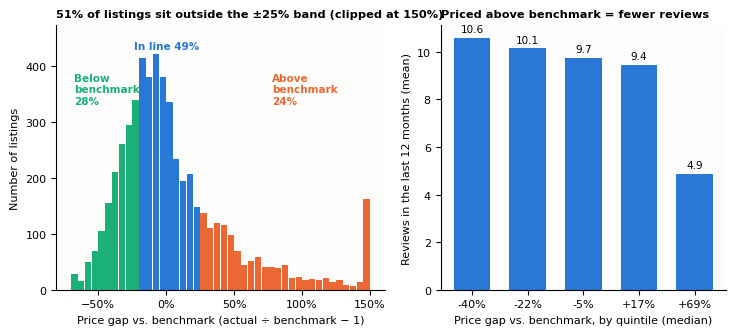

In [17]:
elig = df[(df.first_review <= SCRAPE_DATE - pd.Timedelta(days=365)) & df.review_scores_rating.notna()].copy()
elig["log_gap"] = np.log(elig.price_hkd / elig.pred)         # 0 = priced exactly at the benchmark
elig["acc_log"] = np.log(elig.accommodates)
controls = "C(regime) + C(room_type) + C(neighbourhood_cleansed) + acc_log"
formulas = {"controls": f"number_of_reviews_ltm ~ log_gap + {controls}", "controls + rating": f"number_of_reviews_ltm ~ log_gap + {controls} + review_scores_rating"}
irr = {}                                                     # effect on the number of reviews of a price 10% above the benchmark
for name, formula in formulas.items():
    fit = smf.glm(formula, data=elig, family=sm.families.Poisson()).fit(cov_type="cluster", cov_kwds={"groups": elig.host_id.astype(int)})
    b, se, k = fit.params["log_gap"], fit.bse["log_gap"], np.log(1.10)      # k = "+10% price" on the log scale
    irr[name] = dict(irr_10=float(np.exp(b * k)), lo=float(np.exp((b - 1.96 * se) * k)), hi=float(np.exp((b + 1.96 * se) * k)), p=float(fit.pvalues["log_gap"]))
    print(f"{len(elig):,} listings | {name:18s}: +10% above benchmark -> reviews x{irr[name]['irr_10']:.3f} (95% CI {irr[name]['lo']:.3f}-{irr[name]['hi']:.3f}), p = {irr[name]['p']:.3g}")
RESULTS["demand"] = dict(n=len(elig), irr=irr)

# The same relation as a simple table: five equal-sized groups ("quintiles") by price gap and the average number of reviews of each
elig["gap_group"] = pd.qcut(elig.log_gap, 5, labels=False)   # 0 = cheapest relative to the benchmark ... 4 = most expensive
quint = elig.groupby("gap_group").agg(gap_med=("gap", "median"), rev_mean=("number_of_reviews_ltm", "mean"), n=("gap", "size"))
display(quint.round(2))

# Figure 7: left = histogram of the price gaps, right = reviews by price-gap group
fig, ax = plt.subplots(1, 2, figsize=(7.4, 3.4), gridspec_kw=dict(width_ratios=[1.15, 1]))
a = ax[0]
counts, edges = np.histogram(np.clip(df.gap.values, -0.7, 1.5), bins=np.linspace(-0.7, 1.5, 45))     # gaps beyond the limits are clipped
centers = (edges[:-1] + edges[1:]) / 2
a.bar(centers, counts, width=(edges[1] - edges[0]) * 0.92, color=[PAL["orange"] if c >= TH_HI else (PAL["aqua"] if c <= TH_LO else PAL["blue"]) for c in centers])
a.set_xlabel("Price gap vs. benchmark (actual ÷ benchmark − 1)"); a.set_ylabel("Number of listings")
a.xaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0))
a.text(0.78, counts.max() * 0.92, f"Above\nbenchmark\n{pct(pos_share.get('Above benchmark', 0))}", color=PAL["orange"], fontsize=7.5, fontweight="bold", va="top")
a.text(-0.68, counts.max() * 0.92, f"Below\nbenchmark\n{pct(pos_share.get('Below benchmark', 0))}", color=PAL["aqua"], fontsize=7.5, fontweight="bold", va="top")
a.text(0.0, counts.max() * 1.02, f"In line {pct(pos_share.get('In line', 0))}", color=PAL["blue"], fontsize=7.5, fontweight="bold", ha="center")
a.set_ylim(0, counts.max() * 1.12); a.grid(axis="x", visible=False)
a.set_title(f"{pct(1 - pos_share.get('In line', 0))} of listings sit outside the ±25% band (clipped at 150%)", fontsize=8.2)
b = ax[1]
b.bar(range(5), quint.rev_mean, color=PAL["blue"], width=0.66)
for i, v in enumerate(quint.rev_mean):
    b.text(i, v + 0.25, f"{v:.1f}", ha="center", fontsize=7.5)
b.set_xticks(range(5)); b.set_xticklabels([f"{v*100:+.0f}%" for v in quint.gap_med]); b.grid(axis="x", visible=False)
b.set_xlabel("Price gap vs. benchmark, by quintile (median)"); b.set_ylabel("Reviews in the last 12 months (mean)")
b.set_title("Priced above benchmark = fewer reviews", fontsize=8.2)
fig.tight_layout(w_pad=1.2)
savefig("fig7_price_gap_demand", fig)
RESULTS["gap"] = dict(shares={k: float(v) for k, v in pos_share.items()}, thresholds=[TH_LO, TH_HI], quintiles=quint.reset_index().to_dict(orient="records"))

**Finding.** About half of the listings are priced more than 20-25% away from their benchmark. Among listings of the same kind, **the more a listing is priced above its
benchmark, the fewer reviews it gets** (the most expensive fifth gets about half the reviews of those in line), while discounts do not bring much extra. Careful: this is an
*association* (a listing can be expensive *and* unpopular for a reason we cannot see, such as poor photos), not proof that lowering the price will raise demand.

## 11. Existing listings: do ratings and reviews add information?
The benchmark is for a **new** listing. An operator with a live listing also knows its ratings and review activity. We compare two gradient-boosting models with the same
settings, one with the launch-time factors only and one that also knows the ratings and review activity, on the test hosts.

In [18]:
EXP_FILLED = EXP_ALL.fillna(EXP_ALL.iloc[train_idx].median())      # missing ratings -> training median
XX = pd.concat([X, EXP_FILLED], axis=1)                            # launch-time factors + experience factors
best_gb = gb.best_estimator_                                       # tuned gradient boosting
launch_cols = list(X.columns)
model_launch = clone(best_gb).fit(XX.iloc[train_idx][launch_cols], y_train)
model_exp = clone(best_gb).fit(XX.iloc[train_idx], y_train)                       # all columns: launch-time + experience
has_rating = EXP_ALL.rs_rating.iloc[test_idx].notna().values                       # test listings that have a rating

def test_errors(model, cols, rows):
    return evaluate(p_test[rows], np.exp(model.predict(XX.iloc[test_idx][cols][rows])))

all_rows = np.ones(len(test_idx), dtype=bool)
compare = pd.DataFrame({"Launch-time model (all test)": test_errors(model_launch, launch_cols, all_rows),
                        "+ experience (all test)": test_errors(model_exp, list(XX.columns), all_rows),
                        f"Launch-time model (rated, n={has_rating.sum()})": test_errors(model_launch, launch_cols, has_rating),
                        "+ experience (rated)": test_errors(model_exp, list(XX.columns), has_rating)}).T
display(compare[["MAE", "MedAPE", "Within20", "R2_log"]].round(3))
RESULTS["existing_model"] = {k: r.to_dict() for k, r in compare.iterrows()}

,MAE,MedAPE,Within20,R2_log
Launch-time model (all test),267.035,0.198,0.505,0.802
+ experience (all test),259.135,0.193,0.513,0.810
"Launch-time model (rated, n=568)",337.767,0.240,0.444,0.624
+ experience (rated),326.064,0.223,0.460,0.643


**Finding.** Ratings and review activity improve the prediction only slightly: **guests do not pay a large premium for reputation in this market; the price is mostly set by what the listing is.**

## 12. The decision tool: a price benchmark with a plausible band
A single number invites false precision, so the tool returns **a price and an 80% band**. The band comes from the model's own errors on the training hosts (10th-90th percentile
of the error on the log price, separately for short and monthly stays), and we **check its coverage on the test hosts**: a band labelled "80%" must contain about 80% of unseen listings.

In [19]:
# Band: residual = real log price - predicted log price (predictions from models that did not see the host)
pred_train_oof = cross_val_predict(clone(models[BEST]), X_train, y_train, cv=GroupKFold(n_splits=5), groups=g_train, n_jobs=-1)
resid_train = y_train - pred_train_oof
stay_train, stay_test = X_all.long_stay.iloc[train_idx].values, X_all.long_stay.iloc[test_idx].values
BAND = {s: np.percentile(resid_train[stay_train == s], [10, 90]) for s in (0, 1)}      # 0 = short stay, 1 = monthly stay

pred_test_log = models[BEST].predict(X_test)
low, high = pred_test_log + np.array([BAND[s][0] for s in stay_test]), pred_test_log + np.array([BAND[s][1] for s in stay_test])
inside = (y_test >= low) & (y_test <= high)                          # is the real price inside the band?
coverage_by = {"short": float(inside[stay_test == 0].mean()), "long": float(inside[stay_test == 1].mean())}
print(f"The 80% band covers {pct(inside.mean())} of the unseen listings (short stay {pct(coverage_by['short'])}, long stay {pct(coverage_by['long'])})")
RESULTS["band"] = dict(coverage=float(inside.mean()), coverage_by=coverage_by, q_short=[float(v) for v in BAND[0]], q_long=[float(v) for v in BAND[1]])

# The model used by the tool is trained again on ALL listings; its band comes from the all-listing predictions of section 10
FINAL = clone(models[BEST]).fit(X, y)
BAND_ALL = {s: np.percentile((y - oof)[X_all.long_stay.values == s], [10, 90]) for s in (0, 1)}

The 80% band covers 84% of the unseen listings (short stay 81%, long stay 86%)


**From simple inputs to a prediction.** A host only knows a handful of facts (district, size, location...). `make_row` builds a one-row table from them; everything else takes the
market-typical value (median of each column, most common category) and the distance features are computed from the coordinates. `encode` prepares the row exactly like the
training data and `benchmark` returns the price and the band.

In [20]:
TYPICAL = {c: X_all[c].median() for c in NEW_COLS if c not in CAT_COLS}      # typical listing: median of the numbers ...
TYPICAL.update({c: X_all[c].mode()[0] for c in CAT_COLS})                    # ... and most common value of the categories
UNFLAGGED_AMEN = float(np.median(X_all.n_amenities - X_all[list(AMEN_COLS.values())].sum(axis=1)))   # typical number of amenities outside our 30 flags
BASIC_KIT = ["Wifi", "Air conditioning", "Hot water", "Kitchen", "TV"]       # default amenities of the example listings

def make_row(district, room_type, property_type, accommodates, bedrooms, baths, lat, lon, long_stay=0, weekend=0, amenities=BASIC_KIT, shared_bath=0):
    """One listing (a one-row table) from simple inputs; everything not given takes the market-typical value."""
    r = dict(TYPICAL)
    dist = distance_features([lat], [lon]).iloc[0]
    nights = 30 if long_stay else 2                                          # default minimum stay: 30 nights (monthly) or 2 nights
    r.update(room_type=room_type, property_type_grp=property_type if property_type in TOP_PTYPES else "Other", accommodates=accommodates, bedrooms=bedrooms,
             studio=int(bedrooms == 0), beds=max(1, round(accommodates / 2)), baths=baths, bath_shared=shared_bath, long_stay=long_stay,
             log_min_nights=np.log(nights), q_log_nights=np.log(nights), q_weekend=weekend if not long_stay else 0, pro_host=0, host_local=1,   # an individual host living in Hong Kong
             
             district_grp=district if district in KEEP_DISTRICTS else "Other districts", region=REGION.get(district, "New Territories & Islands"), lat=lat, lon=lon)
    r.update({c: float(dist[c]) for c in ["dist_mtr_km", "n_mtr_1km", "dist_central_km", "dist_tst_km", "dist_hub_min_km"]})
    d = haversine_km(lat, lon, lat_all, lon_all)                              # competition: listings already near this location
    r["listings_500m"], r["listings_1km"] = int((d <= 0.5).sum()), int((d <= 1.0).sum())
    r.update({col: int(a in amenities) for a, col in AMEN_COLS.items()})
    r["n_amenities"] = len(amenities) + UNFLAGGED_AMEN
    return pd.DataFrame([r])[NEW_COLS]

def encode(row_df):
    """Prepare listings like the training data: 0/1 columns for the categories, same columns, training median for missing values."""
    return pd.get_dummies(row_df, columns=CAT_COLS, dtype=int).reindex(columns=X.columns, fill_value=0).fillna(train_median)

def benchmark(row_df):
    """Benchmark price and 80% band (low, high) in HKD for a one-row table."""
    log_price, stay = float(FINAL.predict(encode(row_df))[0]), int(row_df.long_stay.iloc[0])
    return np.exp(log_price), np.exp(log_price + BAND_ALL[stay][0]), np.exp(log_price + BAND_ALL[stay][1])

def station(name):
    """A point about 150 m from an MTR station (to place the example listings)."""
    return MTR.loc[MTR.name == name, ["lat", "lon"]].iloc[0].values + np.array([0.0012, 0.0010])

# Three example listings, each priced for a weekday short stay, a weekend short stay and a monthly stay
PROFILES = {
    "Wan Chai flat\n(1 bed, 2 guests)": dict(district="Wan Chai", room_type="Entire home/apt", property_type="Entire rental unit", accommodates=2, bedrooms=1, baths=1,
                                           lat=station("Wan Chai")[0], lon=station("Wan Chai")[1]),
    "Mong Kok room\n(shared bath)": dict(district="Yau Tsim Mong", room_type="Private room", property_type="Private room in rental unit", accommodates=2, bedrooms=1, baths=1,
                                        shared_bath=1, lat=station("Mong Kok")[0], lon=station("Mong Kok")[1]),
    "Sai Kung house\n(3 bed, 6 guests)": dict(district="Sai Kung", room_type="Entire home/apt", property_type="Entire home", accommodates=6, bedrooms=3, baths=2,
                                             lat=22.3815, lon=114.2700, amenities=BASIC_KIT + ["Washer", "Free parking on premises"])}
STAYS = {"Short stay, weekday": dict(long_stay=0, weekend=0), "Short stay, weekend": dict(long_stay=0, weekend=1), "Monthly stay": dict(long_stay=1, weekend=0)}
rows = []
for name, listing in PROFILES.items():
    for stay_name, stay in STAYS.items():
        price, lo, hi = benchmark(make_row(**listing, **stay))                # "**" passes the dictionary entries as named arguments
        rows.append(dict(profile=name.replace("\n", " "), profile_short=name, stay=stay_name, price=price, lo=lo, hi=hi))
scen = pd.DataFrame(rows)
display(scen[["profile", "stay", "price", "lo", "hi"]].round(0))
RESULTS["scenarios"] = scen.drop(columns="profile_short").to_dict(orient="records")

,profile,stay,price,lo,hi
0,"Wan Chai flat (1 bed, 2 guests)","Short stay, weekday",841.0,497.0,1519.0
1,"Wan Chai flat (1 bed, 2 guests)","Short stay, weekend",936.0,553.0,1691.0
2,"Wan Chai flat (1 bed, 2 guests)",Monthly stay,443.0,310.0,645.0
3,Mong Kok room (shared bath),"Short stay, weekday",457.0,270.0,825.0
4,Mong Kok room (shared bath),"Short stay, weekend",538.0,318.0,972.0
5,Mong Kok room (shared bath),Monthly stay,215.0,151.0,314.0
6,"Sai Kung house (3 bed, 6 guests)","Short stay, weekday",1953.0,1153.0,3527.0
7,"Sai Kung house (3 bed, 6 guests)","Short stay, weekend",2191.0,1293.0,3957.0
8,"Sai Kung house (3 bed, 6 guests)",Monthly stay,1219.0,854.0,1774.0


**What-if levers.** We change one thing of the Wan Chai flat and see how its benchmark moves. We do *not* rank amenities by "model-implied uplift": when a flag such as *hair dryer*
is switched on for budget rooms, the model treats the room as a different (hotel-like) listing and returns implausible jumps; amenities are markers of listing type rather than priced
upgrades. Because single levers depend on the model, we cross-check the two that matter most (*weekend check-in* and *one more guest*) with the average effect over all short-stay
listings under each model.

,lever,price,change
0,Accept monthly stays (28+ nights),443.071,-0.473
1,Weekend check-in (vs. weekday),936.250,0.113
4,Add dedicated workspace,939.474,0.116
2,+1 guest accommodated (sofa bed),957.154,0.137
3,+1 bedroom (sleeps 4),1243.171,0.477


,Weekend check-in (%),+1 guest (%)
Linear regression,10.6,9.8
Random forest,11.9,7.0
Gradient boosting,14.4,10.7


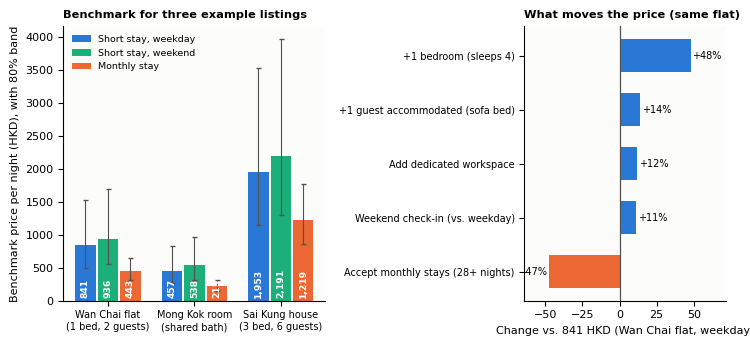

In [21]:
base_listing = {**PROFILES[list(PROFILES)[0]], "long_stay": 0, "weekend": 0}
def bench(**changes):
    """Benchmark price of the Wan Chai flat with some inputs changed, e.g. bench(weekend=1)."""
    return benchmark(make_row(**{**base_listing, **changes}))[0]

base_price = bench()
LEVERS = {"Accept monthly stays (28+ nights)": dict(long_stay=1), "Weekend check-in (vs. weekday)": dict(weekend=1), "+1 guest accommodated (sofa bed)": dict(accommodates=3),
          "+1 bedroom (sleeps 4)": dict(bedrooms=2, accommodates=4), "Add dedicated workspace": dict(amenities=BASIC_KIT + ["Dedicated workspace"])}
lev = pd.DataFrame([dict(lever=k, price=bench(**v), change=bench(**v) / base_price - 1) for k, v in LEVERS.items()]).sort_values("change")
display(lev.round(3))
RESULTS["levers"] = dict(base_price=float(base_price), items=lev.to_dict(orient="records"))

# Cross-check: average effect over all short-stay listings (everybody checks in on a weekend instead of a weekday / gets one more guest)
short = X_all.long_stay == 0
weekday, weekend, more_guests = X[short].copy(), X[short].copy(), X[short].copy()
weekday["q_weekend"], weekend["q_weekend"], more_guests["q_weekend"] = 0, 1, 0
more_guests["accommodates"] = weekday.accommodates + 1
effect = lambda model, after: float(np.exp((model.predict(after) - model.predict(weekday)).mean()) - 1)      # average % change of the predicted price
check = {name: dict(weekend=effect(model, weekend), plus_one_guest=effect(model, more_guests)) for name, model in models.items()}
display((pd.DataFrame(check).T * 100).round(1).rename(columns={"weekend": "Weekend check-in (%)", "plus_one_guest": "+1 guest (%)"}))
RESULTS["lever_check"] = check

# Figure 8: left = benchmark with price band for the three examples, right = what-if levers
fig, ax = plt.subplots(1, 2, figsize=(7.4, 3.5), gridspec_kw=dict(width_ratios=[1.3, 1]))
a = ax[0]
names = list(PROFILES)
xpos, width = np.arange(len(names)), 0.26
for j, (stay_name, col) in enumerate([("Short stay, weekday", PAL["blue"]), ("Short stay, weekend", PAL["aqua"]), ("Monthly stay", PAL["orange"])]):
    sub = scen[scen.stay == stay_name].set_index("profile_short").loc[names]
    a.bar(xpos + (j - 1) * width, sub.price, width * 0.9, color=col, label=stay_name, yerr=[sub.price - sub.lo, sub.hi - sub.price],
          error_kw=dict(ecolor=PAL["ink2"], lw=0.8, capsize=1.8))                 # the whiskers are the 80% band
    for x_, v in zip(xpos + (j - 1) * width, sub.price):
        a.text(x_, 40, f"{v:,.0f}", ha="center", va="bottom", fontsize=6.6, color="white", fontweight="bold", rotation=90)
a.set_xticks(xpos); a.set_xticklabels(names, fontsize=7); a.set_ylabel("Benchmark price per night (HKD), with 80% band")
a.legend(loc="upper left", fontsize=6.8); a.grid(axis="x", visible=False); a.set_title("Benchmark for three example listings", fontsize=8.2)
b = ax[1]
ypos = np.arange(len(lev))
b.barh(ypos, lev.change * 100, color=[PAL["blue"] if v >= 0 else PAL["orange"] for v in lev.change], height=0.62)
b.set_yticks(ypos); b.set_yticklabels(lev.lever, fontsize=7)
for y_, v in zip(ypos, lev.change):
    b.text(v * 100 + (1.2 if v >= 0 else -1.2), y_, f"{v*100:+.0f}%", va="center", ha="left" if v >= 0 else "right", fontsize=7)
b.axvline(0, color=PAL["ink2"], lw=0.9); b.set_xlim(lev.change.min() * 100 * 1.35, max(lev.change.max() * 100 * 1.5, 12))
b.set_xlabel(f"Change vs. {base_price:,.0f} HKD (Wan Chai flat, weekday)"); b.grid(axis="y", visible=False); b.set_title("What moves the price (same flat)", fontsize=8.2)
fig.tight_layout(w_pad=1.2)
savefig("fig8_decision_tool", fig)
save_results()

## 13. "Why this price?" – explaining each prediction in plain language
A host who is told "1,030 HKD" immediately asks **why**. We answer in two steps, separating *computing* from *writing*:
1. **We compute the reasons with SHAP**, a standard explainability method for machine-learning models. SHAP splits the prediction of the selected model into one **contribution per
   factor**: starting from the typical price of Hong Kong listings, each factor pushes this listing's price up or down, and the contributions add up exactly to the prediction.
   We add the contributions of the factors of each business group (size, location & transit, amenities...), so that the result is readable for a host.
2. **A language model (OpenAI API) writes the explanation** from those numbers only. It never sees our data or our model.

*Risks of AI-generated text.* The factors are given to the model in two lists (raising / lowering the price) and a **check** compares every number of its answer with the numbers
we gave it; if one is not supported, a **fixed template** is used instead. Without an API key the template is used too, so the notebook always runs. The key is read from the
environment (`OPENAI_API_KEY`) or a git-ignored `.env` file and is never written to the notebook or the repository.

In [22]:
def read_api_key():
    """The OpenAI key comes from the environment or a local .env file; it is never printed or saved."""
    if os.environ.get("OPENAI_API_KEY"):
        return os.environ["OPENAI_API_KEY"].strip()
    if (ROOT / ".env").exists():
        for line in (ROOT / ".env").read_text(encoding="utf8").splitlines():
            if line.strip().startswith("OPENAI_API_KEY"):
                return line.split("=", 1)[1].strip().strip('"').strip("'")
    return None

OPENAI_KEY, OPENAI_MODEL = read_api_key(), os.environ.get("OPENAI_MODEL", "gpt-4o-mini")
print("LLM explanations:", f"ON (model {OPENAI_MODEL})" if OPENAI_KEY else "OFF - no OPENAI_API_KEY found, the template is used")

# Business labels: the factors that a host recognises, in 9 groups
FACTOR_GROUPS = {
    "Stay length (minimum nights)": ["long_stay", "log_min_nights", "q_log_nights"], "Weekend check-in": ["q_weekend"], "Room type": ["room_type"],
    "Property type": ["property_type_grp"], "Size & capacity": ["accommodates", "bedrooms", "studio", "beds", "baths"], "Shared bathroom": ["bath_shared"],
    "Location & transit": ["district_grp", "region", "lat", "lon"] + FAMILIES["Transit & centrality"], "Local competition": FAMILIES["Local competition"],
    "Amenities": FAMILIES["Amenities"]}

import shap
EXPLAINER = shap.TreeExplainer(FINAL)                                        # SHAP for the selected tree model (contributions in log price)
START_PRICE = float(np.exp(np.ravel(EXPLAINER.expected_value)[0]))           # starting point: typical price of a Hong Kong listing in the model
GROUP_COLS = {label: family_columns(cols) for label, cols in FACTOR_GROUPS.items()}      # model columns of every business group

def factor_effects(row_df):
    """SHAP contribution of every factor group, as the % by which it raises or lowers the price (contributions of log price multiply)."""
    stay = int(row_df.long_stay.iloc[0])
    contributions = pd.Series(EXPLAINER.shap_values(encode(row_df))[0], index=X.columns)       # one number per model column
    effects = {label: float(np.exp(contributions[cols].sum()) - 1) for label, cols in GROUP_COLS.items()
               if not (label == "Weekend check-in" and stay == 1)}           # the check-in day only matters for short stays
    return pd.Series(effects).sort_values(key=abs, ascending=False)

LLM explanations: ON (model gpt-4o-mini)


In [23]:
def make_facts(listing, stay, price, lo, hi, effects):
    """The facts for the language model. The factors go in TWO lists, so that the direction of an effect cannot be confused."""
    top = effects[effects.abs() >= 0.03].head(6)             # effects of at least 3%, at most the 6 largest
    return {"listing": f"{listing['room_type']} in {listing['district']}, {listing['accommodates']} guests, " + ("monthly stay" if stay["long_stay"] else "short stay"),
            "benchmark_price_hkd_per_night": int(round(price, -1)), "band_80pct_hkd": [int(round(lo, -1)), int(round(hi, -1))],
            "typical_hong_kong_listing_price_hkd": int(round(START_PRICE, -1)),
            "note_on_comparison": "the typical Hong Kong listing is the starting point; the factors below explain why this listing is above or below it",
            "factors_associated_with_a_HIGHER_price": [{"factor": k, "higher_by_pct": int(round(100 * v))} for k, v in top.items() if v > 0] or "none",
            "factors_associated_with_a_LOWER_price": [{"factor": k, "lower_by_pct": int(round(-100 * v))} for k, v in top.items() if v < 0] or "none"}

def template_text(f):
    """Fallback without AI: a fixed sentence pattern filled with the numbers."""
    up, down = f["factors_associated_with_a_HIGHER_price"], f["factors_associated_with_a_LOWER_price"]
    text = (f"The benchmark for this listing ({f['listing']}) is about {f['benchmark_price_hkd_per_night']:,} HKD per night (80% band {f['band_80pct_hkd'][0]:,}-{f['band_80pct_hkd'][1]:,}), "
            f"compared with about {f['typical_hong_kong_listing_price_hkd']:,} HKD for the typical Hong Kong listing. ")
    if up != "none":
        text += "Associated with a higher price: " + "; ".join(f"{x['factor'].lower()} (+{x['higher_by_pct']}%)" for x in up) + ". "
    if down != "none":
        text += "Associated with a lower price: " + "; ".join(f"{x['factor'].lower()} (-{x['lower_by_pct']}%)" for x in down) + ". "
    return text + "These are statistical associations, not guarantees."

SYSTEM_PROMPT = ("You are a pricing analyst explaining a rental price benchmark to a Hong Kong host. Write 3-5 plain-English sentences (at most 120 words), no bullet points, no advice. "
                 "Use ONLY the facts and numbers in the JSON; never invent anything. Say the benchmark price and the 80% band, compare it with the typical Hong Kong listing, "
                 "then name the factors: those in the HIGHER list raise the price, those in the LOWER list lower it, with their percentages. "
                 "Use the words 'associated with', not 'causes'.")

def call_openai(facts):
    """Send the facts to the OpenAI API and return the answer (temperature 0 = as repeatable as possible)."""
    response = requests.post("https://api.openai.com/v1/chat/completions", headers={"Authorization": f"Bearer {OPENAI_KEY}"}, timeout=45,
                             json={"model": OPENAI_MODEL, "temperature": 0, "max_tokens": 260,
                                   "messages": [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": json.dumps(facts)}]})
    response.raise_for_status()                                              # stops with an error if, e.g., the key is wrong
    return response.json()["choices"][0]["message"]["content"].strip()

def numbers_ok(text, facts):
    """True if every number of the text matches (within 3%, or +-1 for small values) a number of the facts we sent."""
    allowed = [float(x) for x in re.findall(r"\d+(?:\.\d+)?", json.dumps(facts).replace(",", ""))] + [80.0]    # 80 = the "80% band"
    written = [float(x) for x in re.findall(r"\d+(?:\.\d+)?", text.replace(",", ""))]
    return all(any(abs(x - a) <= max(1.0, 0.03 * a) for a in allowed) for x in written)


=== Wan Chai flat (1 bed, 2 guests) - 841 HKD (band 497-1,519) [OpenAI gpt-4o-mini]
The benchmark price for your listing is HKD 840 per night, with an 80% band ranging from HKD 500 to HKD 1,520. In
comparison, the typical Hong Kong listing price is HKD 490. Factors associated with a higher price include a minimum
stay length (39%), room type (18%), location and transit (13%), and property type (6%). Conversely, factors associated
with a lower price are size and capacity (11%) and amenities (7%).

=== Mong Kok room (shared bath) - 457 HKD (band 270-825) [OpenAI gpt-4o-mini]
The benchmark price for your listing is HKD 460 per night, with an 80% band ranging from HKD 270 to HKD 820. The typical
Hong Kong listing price is HKD 490, which is slightly higher than your benchmark. Factors associated with a higher price
include a minimum stay length, which raises the price by 45%. Conversely, factors associated with a lower price include
location and transit (10%), room type (9%), size and capa

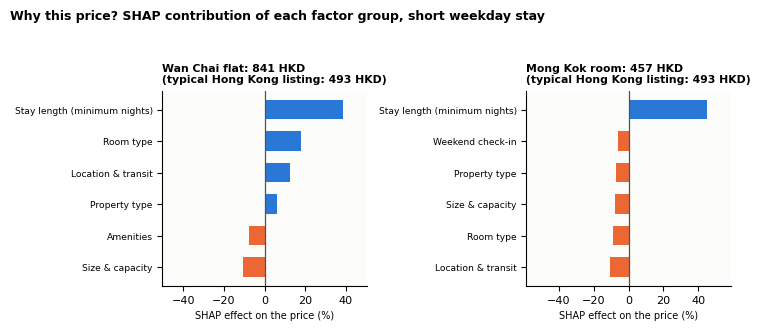

In [24]:
def explain_price(listing, stay):
    """Benchmark price, band, reasons and explanation text for one listing."""
    row = make_row(**listing, **stay)
    price, lo, hi = benchmark(row)
    effects = factor_effects(row)
    facts = make_facts(listing, stay, price, lo, hi, effects)
    text, source = template_text(facts), "template"                          # by default: the template
    if OPENAI_KEY:
        try:                                                                 # try the language model; any failure falls back to the template
            answer = call_openai(facts)
            if numbers_ok(answer, facts):
                text, source = answer, f"OpenAI {OPENAI_MODEL}"
        except Exception as e:
            print("LLM call failed, template used:", type(e).__name__)
    return dict(price=price, lo=lo, hi=hi, effects=effects, text=text, source=source)

# Explain the three example listings (weekday short stay) and the Wan Chai flat as a monthly stay
cases = [(name, listing, STAYS["Short stay, weekday"]) for name, listing in PROFILES.items()] + [("Wan Chai flat, monthly stay", list(PROFILES.values())[0], STAYS["Monthly stay"])]
EXPLANATIONS = {name: explain_price(listing, stay) for name, listing, stay in cases}
for name, e in EXPLANATIONS.items():
    print(f"\n=== {name.replace(chr(10), ' ')} - {e['price']:,.0f} HKD (band {e['lo']:,.0f}-{e['hi']:,.0f}) [{e['source']}]\n{textwrap.fill(e['text'], 120)}")
RESULTS["explanations"] = dict(
    llm_enabled=bool(OPENAI_KEY), model=OPENAI_MODEL if OPENAI_KEY else None, start_price=START_PRICE,
    items=[dict(profile=name.replace("\n", " "), price=float(e["price"]), source=e["source"], text=e["text"])
           for name, e in EXPLANATIONS.items()])

# Figure 9: blue = factor groups that raise the price, orange = factor groups that lower it (relative to comparable listings); the 6 largest effects
fig, axes = plt.subplots(1, 2, figsize=(7.4, 3.3))
for ax, name in zip(axes, list(PROFILES)[:2]):
    e = EXPLANATIONS[name]
    eff = e["effects"].head(6).sort_values()
    ax.barh(range(len(eff)), eff.values * 100, color=[PAL["blue"] if v > 0 else PAL["orange"] for v in eff.values], height=0.62)
    ax.set_yticks(range(len(eff))); ax.set_yticklabels(eff.index, fontsize=6.6); ax.grid(axis="y", visible=False)
    ax.set_xlim(-1.3 * np.abs(eff.values).max() * 100, 1.3 * np.abs(eff.values).max() * 100); ax.axvline(0, color=PAL["ink2"], lw=0.9); ax.set_xlabel("SHAP effect on the price (%)", fontsize=7)
    ax.set_title(f"{name.splitlines()[0]}: {e['price']:,.0f} HKD\n(typical Hong Kong listing: {START_PRICE:,.0f} HKD)", fontsize=7.8)
fig.suptitle("Why this price? SHAP contribution of each factor group, short weekday stay", x=0.01, ha="left", fontsize=9, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.93))
savefig("fig9_explanation", fig)
save_results()

**Finding.** For each listing we can say *why* the benchmark is what it is: which factors push it above or below the typical Hong Kong listing, and by how much.
The wording comes from a language model, but every number in it comes from SHAP and is verified before it is shown.

## 14. Summary, decisions and limitations
**The story in five sentences**
1. Hong Kong rentals are **two markets**, tourist stays and monthly rentals; stay length is the master variable of the price.
2. A machine-learning benchmark predicts a fair price clearly better than "look at comparable listings", on hosts it has never seen.
3. **Listing type, stay type and the operator** explain most of the price; **distance to the MTR does not** differentiate prices on its own.
4. Listings priced **far above** their benchmark get **fewer reviews**; discounts do not clearly buy more.
5. Every price comes with a **band** and a **"why this price?"** explanation whose numbers are computed by us and checked.

**Decisions we made (and why)**
| Decision | Reason |
|---|---|
| Drop listings without a price; remove prices < 50 HKD or above the 99.5th percentile | A benchmark is about bookable listings; data errors and a few luxury outliers would dominate the errors |
| Treat **stay length as a core factor** and a segmentation (≥ 28 nights) | The price is a quote for a specific stay; monthly stays cost a fraction per night |
| Add quote-context controls (nights, weekend check-in) but **not the lead time** | Lead time partly reflects demand (leakage) |
| Model `log(price)` | Percentage errors, tamed skewness |
| Split and cross-validate **by host**; test set used once; models chosen by cross-validation | Prevents memorising professional hosts; honest estimate |
| Compare with the **comparable-listings baseline** | The business question is "better than what I do now?" |
| Two host flags only; no ratings or reviews in the launch-time model | Richer host variables did not help on unseen hosts; a new host has no reviews |
| Explain with permutation importance on unseen hosts and say *association* | Observational data, no causal claims |
| Segment with KMeans **without price**, minimum segment size | Price differences between segments are findings; segments big enough to matter |
| Report a band and verify its coverage; no amenity "uplift" ranking | Avoids false precision; amenities mostly mark the listing type |
| Keep the code simple: basic pandas / NumPy / scikit-learn tools and SHAP for the explanations | The analysis must be readable and reproducible by the whole group |

**Limitations**
* The price is an **asking price quoted for one stay** (not a transaction price or revenue); seasonality beyond weekday/weekend is not modelled; listings without a price (mostly not
  bookable) and luxury listings above the 99.5th percentile are out of scope.
* Demand is observed only through **reviews** (a proxy); the price-gap → demand result is an association and could be driven by unobserved quality (photos, view, floor).
* Licence status is empty in the data; straight-line distances ignore hills and walking routes; the MTR data come from a volunteer-maintained map; the data are a single snapshot (25 Sep 2026).

In [25]:
RESULTS["meta"] = dict(random_state=SEED, model_best=BEST, k_segments=K_SEG)
save_results()
print("Saved outputs/results.json and", len(list(FIG.glob("*.png"))), "figures in outputs/figures/")

Saved outputs/results.json and 10 figures in outputs/figures/
